<table style="background-color: transparent;">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1">Computación Cuántica</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">2027-1</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="6" color="#6366F1">Laboratorio 6: Algoritmos Cuánticos IV</font></td>
    </tr>
</table>

---
<h3>Autores:</h3>

<h4>
- Naomi Reyes Granados<br>
- Sebastián González Juárez<br>
- Owen Charbel Sam Ramírez <br>
- Angel Carmona Zavaleta
</h4>

<p>
Este notebook está adaptado del material desarrollado originalmente por
<b>Claudia Zendejas Morales</b>, el cual constituye la base principal de este
notebook. Sobre dicho material se realizaron modificaciones, ampliaciones y
adaptaciones para su uso en esta clase.
</p>

---

<p style="text-align:right; font-weight:bold;">Autora: Claudia Zendejas-Morales</p>

$ \newcommand{\bra}[1]{\langle #1|} $
$ \newcommand{\ket}[1]{|#1\rangle} $
$ \newcommand{\braket}[2]{\langle #1|#2\rangle} $
$ \newcommand{\mymatrix}[2]{\left[ \begin{array}{#1} #2\end{array} \right]} $
$ \newcommand{\myvector}[1]{\mymatrix{c}{#1}} $

## Contenido

1. [Introducción](#1)
2. [Transformada Cuántica de Fourier (QFT)](#2)
   1. [Transformada Discreta de Fourier](#2.1)
   2. [Transformada Cuántica de Fourier](#2.2)
   3. [Implementación del Circuito](#2.3)
   4. [Implementación en Qiskit](#2.4)
   5. [QFT Inversa](#2.5)
3. [ Estimación Cuántica de Fase](#3)
   1. [Algoritmo de QPE](#3.1)
   2. [Implementación en Qiskit](#3.2)
4. [Práctica 6](#4)

In [29]:
!pip install qiskit
!pip install pylatexenc

<a id="1"></a>
# 1. Introducción

El **algoritmo de Shor** es uno de los algoritmos más conocidos en computación cuántica debido a su capacidad para factorizar números enteros de manera eficiente, una tarea que es computacionalmente difícil para las computadoras clásicas. La factorización eficiente tiene importantes implicaciones en áreas como la **criptografía**, ya que muchos sistemas de seguridad se basan en la dificultad de factorizar números grandes.

Este algoritmo combina técnicas cuánticas y clásicas para resolver el problema de factorización. Sin embargo, para entender y ejecutar el algoritmo de Shor, es necesario conocer varios conceptos fundamentales y subrutinas. Estos componentes forman la base del algoritmo y se utilizan en diferentes etapas del proceso de factorización.

A continuación, se presenta el **diagrama de bloques del algoritmo de Shor**. Este diagrama ilustra cómo está estructurado el algoritmo, destacando las principales subrutinas y bloques de procesamiento clásico y cuántico:

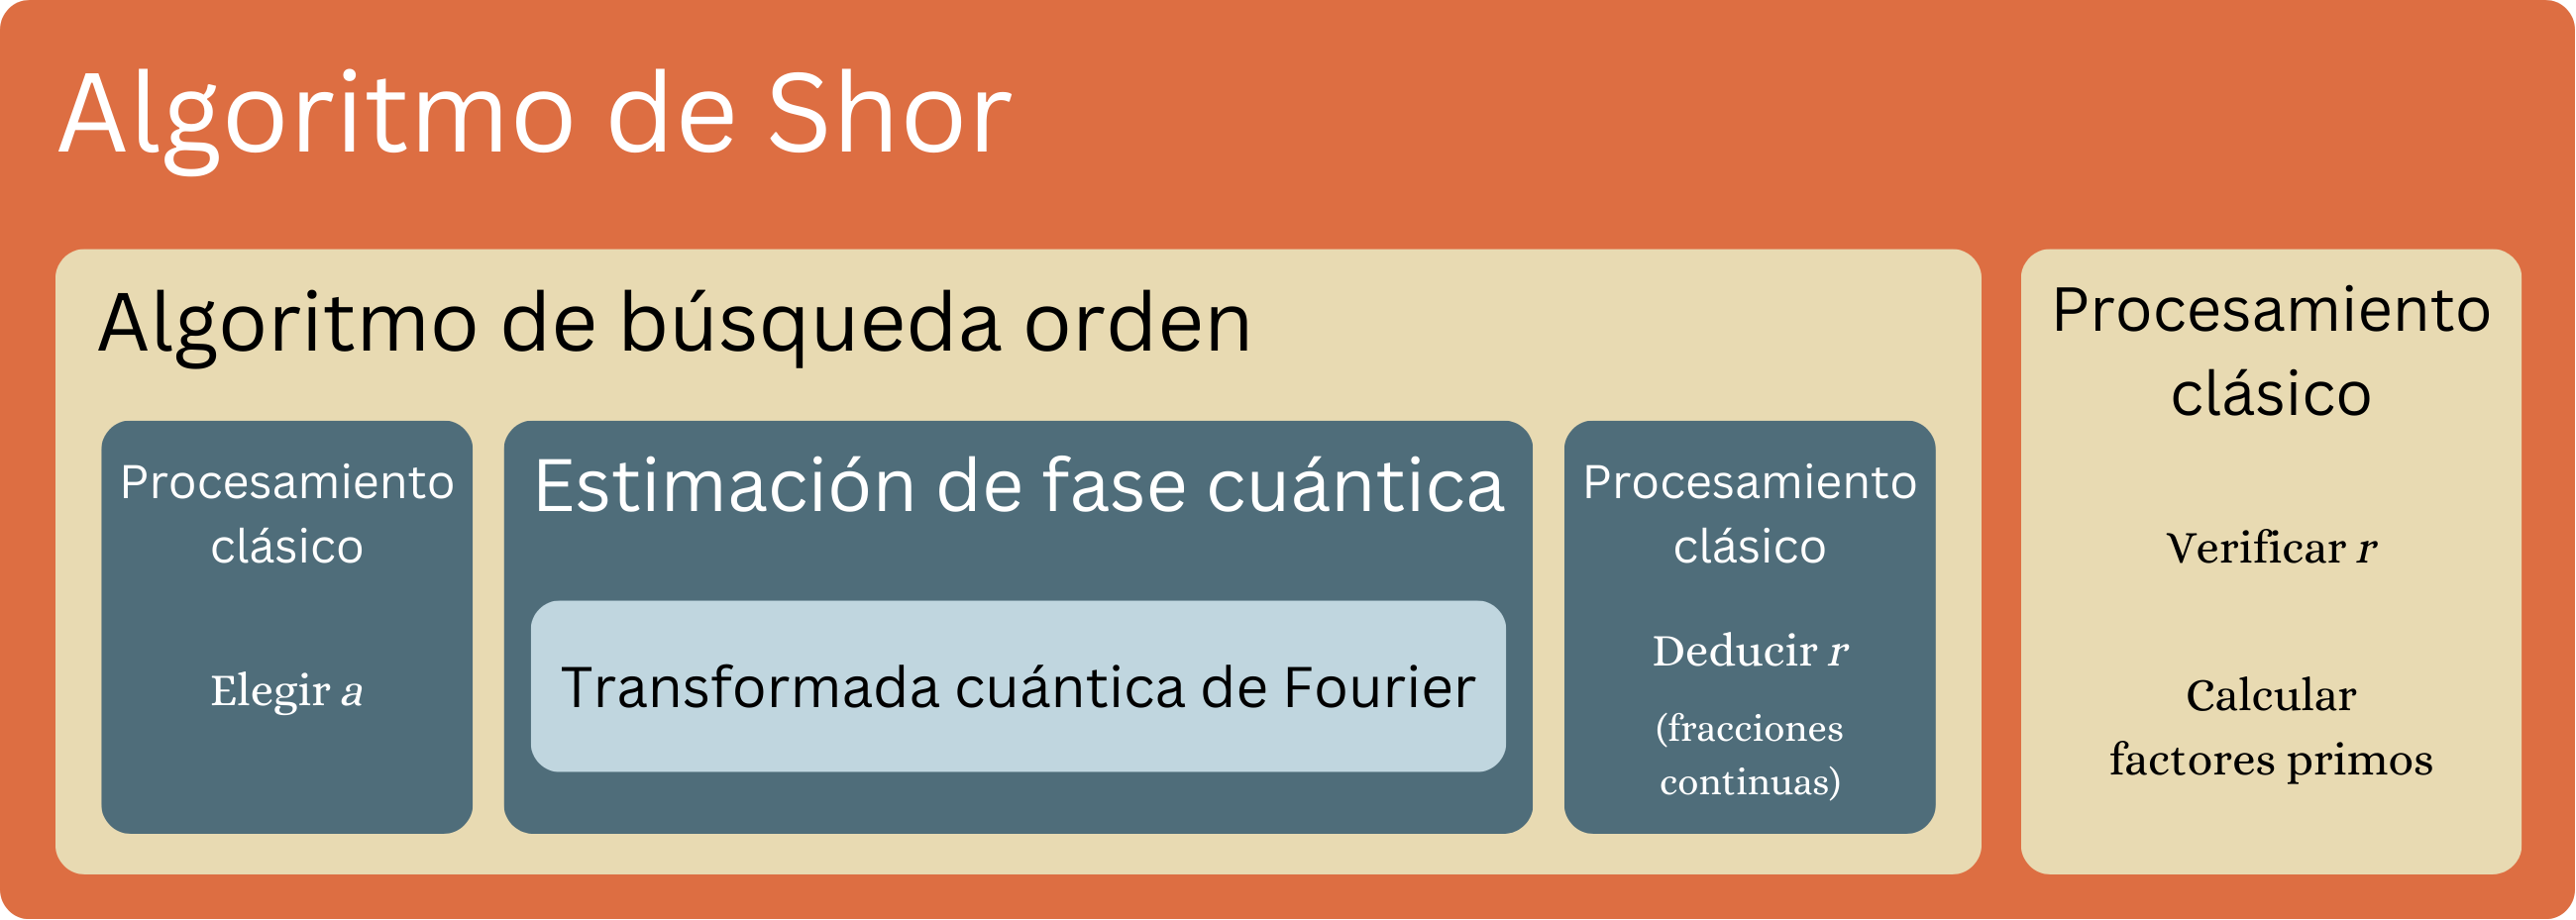

- **Transformada Cuántica de Fourier (QFT)**: Es una subrutina cuántica utilizada para obtener información sobre las fases.
- **Estimación de Fase Cuántica (QPE)**: Utiliza la QFT para estimar la fase de un operador unitario, lo cual es crucial en la búsqueda de órdenes.
- **Algoritmo de Búsqueda de Orden**: Esta es la parte cuántica central del algoritmo de Shor. Utiliza QPE para encontrar el periodo u _orden_ de una función, que es clave para la factorización.
- **Procesamiento Clásico**: El algoritmo de Shor también requiere bloques de procesamiento clásico. Estos bloques se encargan de la preparación inicial (como la elección de parámetros), la interpretación de los resultados cuánticos, y finalmente la verificación y cálculo de los factores primos.

Este diagrama refleja el orden de construcción que seguiremos en los siguientes dos notebooks, desde los componentes más internos (como la $QFT$) hasta el conjunto completo del algoritmo de Shor.

<a id="2"></a>
# 2. Transformada Cuántica de Fourier ($QFT$)

Las transformaciones son muy populares en matemáticas y ciencias de la computación, ya que permiten *transformar* un problema en otro cuya solución se conoce o resulta más sencilla de obtener.

Una de estas herramientas es la **Transformada de Fourier**, que permite descomponer una señal en sus distintas componentes de frecuencia. Esto resulta especialmente útil en áreas como el procesamiento de señales, el análisis de imágenes y las telecomunicaciones.

En computación cuántica, la **Transformada Cuántica de Fourier (QFT)** actúa sobre las amplitudes de los estados cuánticos y puede implementarse mediante circuitos eficientes. Esta propiedad la convierte en una herramienta importante para algoritmos cuánticos como el de Shor y la estimación de fase.

Primero veamos la versión clásica, la **Transformada Discreta de Fourier (DFT)**, que nos ayudará a comprender mejor el funcionamiento de su versión cuántica, la **QFT**.

<a id="2.1"></a>
## 2.1. Transformada Discreta de Fourier

### De la señal muestreada al vector $\vec{x}$

En procesamiento digital de señales, una señal continua $x(t)$ se **muestrea** cada $T_s = 1/f_s$ segundos ($f_s$ es la *frecuencia de muestreo*) y se conservan $N$ muestras:

$$
x_j = x(jT_s), \qquad j = 0, 1, \dots, N-1 .
$$

Las agrupamos en el vector $\vec{x}=\begin{pmatrix}x_0 & x_1 & \cdots & x_{N-1}\end{pmatrix}^T\in\mathbb{C}^N$. La **DFT** responde a la pregunta *¿cuánto de cada frecuencia contiene $\vec{x}$?*: expresa $\vec{x}$ como combinación lineal de $N$ sinusoides complejas de frecuencias $0,\tfrac{1}{N},\dots,\tfrac{N-1}{N}$ ciclos por muestra.

### Definición

Sea $\omega_N = e^{2\pi i/N}$ la raíz $N$-ésima primitiva de la unidad. La **Transformada Discreta de Fourier** de $\vec{x}$ es el vector $\vec{y}=\begin{pmatrix}y_0 & y_1 & \cdots & y_{N-1}\end{pmatrix}^T$ cuyas componentes son

$$
y_k=\frac{1}{\sqrt{N}} \sum_{j=0}^{N-1} \omega_N^{\,jk}\,x_j=\frac{1}{\sqrt{N}} \sum_{j=0}^{N-1} e^{\frac{2\pi i\,jk}{N}}\,x_j, \qquad k=0,1,\dots,N-1 .
$$

<div class="alert alert-block alert-info">
<strong>Convención</strong>: esta es la convención "cuántica" (exponente positivo y factor unitario $1/\sqrt{N}$).

En procesamiento de señales (y en `np.fft.fft`) lo usual es $X_k=\sum_{j} e^{-2\pi i\,jk/N}x_j$, con exponente negativo y sin normalizar. Ambas se relacionan por

$$
y_k=\frac{1}{\sqrt{N}}\,X_{(-k)\bmod N}, \qquad\text{es decir,}\qquad \vec{y}=\sqrt{N}\;\mathrm{ifft}(\vec{x}).
$$

Para una señal **real** se cumple $X_{N-k}=\overline{X_k}$, de modo que $\lvert y_k\rvert=\lvert X_k\rvert/\sqrt{N}$: los espectros de magnitud coinciden salvo por la constante $1/\sqrt{N}$.
</div>

### Forma matricial: la DFT es un cambio de base unitario

La definición es una transformación **lineal**, así que se escribe como $\vec{y}=F_N\vec{x}$ con la matriz $N\times N$

$$
(F_N)_{kj}=\frac{\omega_N^{\,jk}}{\sqrt{N}} .
$$

Por ejemplo, para $N=4$ se tiene $\omega_4=i$ y

$$
F_4=\frac{1}{2}\begin{pmatrix}
1 & 1 & 1 & 1\\
1 & i & -1 & -i\\
1 & -1 & 1 & -1\\
1 & -i & -1 & i
\end{pmatrix}.
$$

**Lema (ortogonalidad de las raíces de la unidad).** Para todo entero $m$,

$$
\sum_{j=0}^{N-1}\omega_N^{\,jm}=\begin{cases}N, & \text{si } N\mid m,\\[1mm] 0, & \text{si } N\nmid m.\end{cases}
$$

*Demostración.* Si $N\mid m$, cada término vale $1$. En otro caso $\omega_N^{m}\neq 1$ y la suma es geométrica: $\dfrac{1-\omega_N^{Nm}}{1-\omega_N^{m}}=0$, pues $\omega_N^{Nm}=(\omega_N^{N})^{m}=1$. $\blacksquare$

**Proposición (unitariedad).** $F_N^\dagger F_N=I$.

*Demostración.* Como $(F_N^\dagger)_{aj}=\overline{(F_N)_{ja}}=\omega_N^{-ja}/\sqrt{N}$,

$$
(F_N^\dagger F_N)_{ab}=\frac{1}{N}\sum_{j=0}^{N-1}\omega_N^{-ja}\,\omega_N^{\,jb}=\frac{1}{N}\sum_{j=0}^{N-1}\omega_N^{\,j(b-a)}=\delta_{ab},
$$

porque $\lvert b-a\rvert<N$ y, por el Lema, la suma solo no se anula cuando $b=a$. $\blacksquare$

De la unitariedad se obtienen tres consecuencias:

1. **Inversa.** $\vec{x}=F_N^\dagger\vec{y}$, es decir, $x_j=\dfrac{1}{\sqrt{N}}\displaystyle\sum_{k=0}^{N-1}\omega_N^{-jk}\,y_k$ (la DFT inversa).
2. **Parseval.** $\displaystyle\sum_{k=0}^{N-1}\lvert y_k\rvert^2=\sum_{j=0}^{N-1}\lvert x_j\rvert^2$: la energía de la señal se conserva.
3. **Cambio de base.** Las columnas de $F_N^\dagger$, $\;\vec{u}_k=\frac{1}{\sqrt{N}}\begin{pmatrix}1 & \omega_N^{-k} & \omega_N^{-2k} & \cdots\end{pmatrix}^T$, forman una base ortonormal de $\mathbb{C}^N$ y $y_k=\langle\vec{u}_k,\vec{x}\rangle$ es la coordenada de $\vec{x}$ en la dirección de la sinusoide $\vec{u}_k$.

La **linealidad** implica además que $\mathrm{DFT}(a\vec{x}+b\vec{z})=a\,\mathrm{DFT}(\vec{x})+b\,\mathrm{DFT}(\vec{z})$: el espectro de una suma de señales es la suma de sus espectros.

> **¿Por qué nos importa?** Toda compuerta cuántica es una matriz unitaria. El factor $1/\sqrt{N}$ es justo lo que hace que $F_N$ lo sea, y eso permitirá definir la **QFT** como un operador cuántico que actúa sobre las amplitudes de un estado.

<div class="alert alert-block alert-info">
<strong>Ejemplo</strong>:

$$ $$
Dado $\vec{x}=\begin{pmatrix}1\\2\end{pmatrix}$ transformarlo con DFT para obtener $\vec{y}$.

Cuando $k=0$:

$$
y_0=\frac{1}{\sqrt{2}} \sum_{j=0}^{1}e^{\frac{2\pi i\,j\cdot 0}{2}}x_j= \frac{1}{\sqrt{2}}(x_0+x_1) = \frac{3}{\sqrt{2}}
$$

Cuando $k=1$:

$$
y_1=\frac{1}{\sqrt{2}} \sum_{j=0}^{1}e^{\frac{2\pi i\,j\cdot 1}{2}}x_j= \frac{1}{\sqrt{2}} \left( e^{0}\,x_0 + e^{\pi i}\,x_1 \right) = \frac{1-2}{\sqrt{2}}=\frac{-1}{\sqrt{2}},
$$

usando la identidad de Euler $e^{\pi i}=-1$. Entonces,

$$\vec{y}=\begin{pmatrix}\dfrac{3}{\sqrt{2}} \\ \dfrac{-1}{\sqrt{2}}\end{pmatrix}.$$

En forma matricial, $F_2=\dfrac{1}{\sqrt{2}}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$, que es exactamente la **compuerta de Hadamard** $H$. Esto no es casualidad: veremos que la QFT de un solo qubit es $H$.
</div>

### La DFT identifica periodos

**Proposición (tren de impulsos).** Sea $r$ un divisor de $N$ y sea $x_j=1$ si $r\mid j$ y $x_j=0$ en otro caso ($j=0,\dots,N-1$). Con $M=N/r$,

$$
y_k=\begin{cases}\dfrac{M}{\sqrt{N}}=\dfrac{\sqrt{N}}{r}, & \text{si } M\mid k,\\[3mm] 0, & \text{si } M\nmid k.\end{cases}
$$

*Demostración.* Los únicos términos no nulos son $j=rm$ con $m=0,\dots,M-1$. Como $\omega_N^{\,r}=e^{2\pi i\,r/N}=e^{2\pi i/M}=\omega_M$,

$$
y_k=\frac{1}{\sqrt{N}}\sum_{m=0}^{M-1}\omega_N^{\,rmk}=\frac{1}{\sqrt{N}}\sum_{m=0}^{M-1}\omega_M^{\,mk},
$$

y el Lema (con $M$ en lugar de $N$) da $M/\sqrt{N}$ si $M\mid k$ y $0$ en otro caso. $\blacksquare$

**Lectura de la proposición:**

- El espectro tiene exactamente $r$ picos, en $k=0,M,2M,\dots,(r-1)M$, **separados por $\Delta k=N/r$**: un periodo corto en el tiempo ($r$ pequeño) produce picos muy espaciados en frecuencia, y viceversa.
- Todos los picos miden $\sqrt{N}/r$. En particular $y_0=\frac{1}{\sqrt{N}}\sum_j x_j=\sqrt{N}\,\bar{x}$ es la componente de **corriente directa** (DC), proporcional al promedio de la señal.
- Para $N=100$ y $r=5$: $M=20$, los picos están en $k=0,20,40,60,80$ y miden $\sqrt{100}/5=2$.
- Los valores $y_k$ resultan reales porque el tren es par módulo $N$ ($x_j=x_{N-j}$); en general $y_k\in\mathbb{C}$ y conviene graficar $\lvert y_k\rvert$.
- Si el tren comienza en un desfase $s$, cada $y_k$ solo se multiplica por la fase $\omega_N^{\,sk}$: la posición y la altura de los picos no cambian (lo retomaremos en 2.2 como *desplazamiento lineal*).

**Interpretación como procesamiento de señales.** El índice $k$ corresponde a la frecuencia $f_k=k\,f_s/N$ (resolución $\Delta f=f_s/N$). Un tren con $r$ muestras por periodo tiene frecuencia fundamental $f_0=f_s/r=(N/r)\,f_s/N$, es decir, el bin $k=N/r$; los demás picos son sus armónicos. Para señales reales $y_{N-k}=\overline{y_k}$, así que solo los bins $0\le k\le N/2$ (hasta la frecuencia de Nyquist $f_s/2$) son independientes; los de $k>N/2$ son imágenes espejo. En el ejemplo: $k=0$ es la DC, $k=20$ la fundamental, $k=40$ el segundo armónico, y $k=60,80$ reflejan a $k=40,20$.

**Dos señales.** Si $\vec{x}$ tiene periodo $r_1$ y $\vec{z}$ tiene periodo $r_2$ (ambos divisores de $N$), por linealidad $\mathrm{DFT}(\vec{x}+\vec{z})=\mathrm{DFT}(\vec{x})+\mathrm{DFT}(\vec{z})$, y el espectro presenta picos en los múltiplos de

$$
\frac{N}{r_1}\qquad\text{y}\qquad\frac{N}{r_2}.
$$

<div class="alert alert-block alert-success">
<strong>Cuando $r$ no divide a $N$</strong>: la suma de la demostración deja de ser una suma completa de raíces de la unidad y ya no se cancela exactamente: aparece **fuga espectral** (los picos se ensanchan y su energía se reparte entre bins vecinos). Por ejemplo, con $N=100$ y $r=7$, $96$ de los $100$ coeficientes son distintos de cero y los máximos se agrupan alrededor de $k\approx t\,N/r\approx 14.29\,t$. Este es el caso típico del algoritmo de Shor, pues $N=2^n$ casi nunca es múltiplo del periodo $r$: los picos solo son *aproximados*.
</div>

<a id="2.1.1"></a>
## 2.1.1. Aplicaciones de la Transformada Discreta de Fourier

La DFT es una de las herramientas centrales del procesamiento digital de señales, porque **cambia de representación** (de tiempo a frecuencia) y muchas operaciones son más simples en frecuencia:

- **Análisis espectral:** identificar las frecuencias presentes en audio, vibraciones, señales biomédicas o datos experimentales (el bin $k$ corresponde a $k\,f_s/N$ Hz).
- **Filtrado y eliminación de ruido:** se transforma, se anulan o atenúan los bins no deseados y se regresa con la DFT inversa.
- **Convolución rápida:** la convolución circular se vuelve un producto punto a punto, $\mathrm{DFT}(\vec{x}\circledast\vec{z})=\sqrt{N}\;\mathrm{DFT}(\vec{x})\odot\mathrm{DFT}(\vec{z})$ (el factor $\sqrt{N}$ aparece con la normalización unitaria). Con relleno de ceros se obtiene la convolución lineal, base del filtrado FIR y de la correlación.
- **Imágenes:** la DFT bidimensional permite filtrar y comprimir según el contenido en frecuencia (JPEG usa la DCT, una transformada emparentada).
- **Telecomunicaciones:** OFDM (Wi-Fi, LTE/5G, TV digital) modula y demodula muchas subportadoras con una IFFT y una FFT.

**Costo computacional.** Evaluar la definición directamente requiere calcular $N$ coeficientes con $N$ términos cada uno, es decir, $O(N^2)$ multiplicaciones complejas. La **Transformada Rápida de Fourier (FFT)** de Cooley–Tukey separa los índices pares e impares para reducir una DFT de tamaño $N$ a dos de tamaño $N/2$ más $O(N)$ operaciones, lo que da la recurrencia $T(N)=2T(N/2)+O(N)$ y, por tanto, $O(N\log N)$ (especialmente eficiente cuando $N=2^n$). Gracias a ello la DFT es práctica en telecomunicaciones, procesamiento de información y análisis de datos.

**Puente hacia la QFT.** La DFT convierte un periodo $r$ en picos separados por $N/r$; leer esa separación permite recuperar $r$. La **QFT** realiza esta misma transformación sobre las $N=2^n$ amplitudes de un estado de $n$ qubits y es la pieza que usaremos en la búsqueda de orden del algoritmo de Shor.

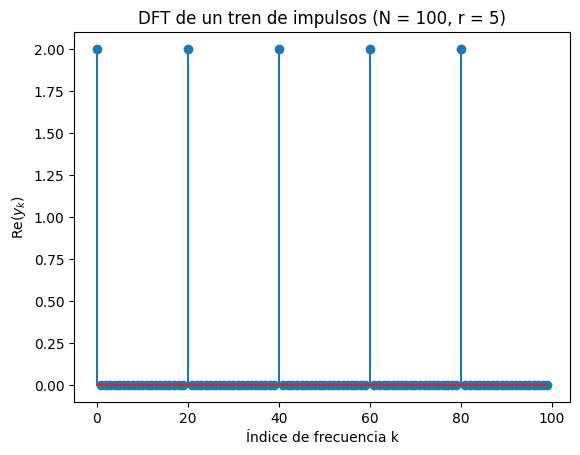

Máximo de y_k            : 2.0
Posiciones de los picos  : [0, 20, 40, 60, 80]
máx |Im(y_k)|            : 1.7263968032921184e-14
¿lazo doble == F·x?      : True
¿F·x == √N·ifft(x)?      : True
¿F es unitaria (F†F=I)?  : True
‖x‖ y ‖y‖ (Parseval)     : 4.47213595499958 4.472135954999579


In [30]:
# ══════════════════════════════════════════════════════════════════════════════
#  DFT unitaria "a mano": tren de impulsos de periodo r = 5 con N = 100 muestras
#  Convención:  y_k = (1/√N) · Σ_{j=0}^{N-1} e^{+2πi·jk/N} · x_j      (k = 0, ..., N-1)
# ══════════════════════════════════════════════════════════════════════════════

# ── 0. Importaciones ──────────────────────────────────────────────────────────
from cmath import exp              # exp(z) = e^z para z COMPLEJO (math.exp solo acepta reales)
from math import pi, sqrt          # pi = π ≈ 3.14159...;  sqrt(a) = √a, para a real ≥ 0
import matplotlib.pyplot as plt    # biblioteca de gráficas (se usa también en la Mini actividad 1)
import numpy as np                 # arreglos y álgebra lineal; solo se usa en la verificación (parte 4)

# ── 1. Construcción de la señal de entrada x ─────────────────────────────────
N = 100                            # número de muestras = longitud del vector x (no tiene que ser 2^n)
r = 5                              # periodo de la señal: hay un impulso cada r muestras (r divide a N)
x = []                             # lista vacía; x[j] será la muestra j-ésima, j = 0, 1, ..., N-1

for j in range(N):                 # recorre los índices j = 0, 1, ..., N-1
    if j % r == 0:                 # '%' es el módulo: (j mod r) == 0  ⇔  j es múltiplo de r
        x.append(1)                # impulso unitario en j = 0, 5, 10, ..., 95  (x_j = 1)
    else:                          # en cualquier otro índice...
        x.append(0)                # ...la señal vale cero (x_j = 0)

# ── 2. DFT directa, aplicando la definición (costo: N² = 10 000 multiplicaciones complejas) ──
y = []                             # aquí guardaremos los N coeficientes de salida y_0, ..., y_{N-1}

for k in range(N):                 # lazo externo: una iteración por cada coeficiente de salida y_k
    s = 0                          # acumulador de la suma Σ_j (inicia en 0; pasa a ser complejo al sumar)
    for j in range(N):             # lazo interno: recorre las N muestras de entrada x_j
        s += exp(2*pi*1j * j * k / N) * x[j]
        # 1j            → unidad imaginaria i de Python
        # 2*pi*1j*j*k/N → número imaginario puro 2πi·jk/N  (el ángulo, en radianes, de la fase)
        # exp(...)      → ω^{jk} = e^{2πi·jk/N}: número complejo de módulo 1 (punto del círculo
        #                 unidad); es la entrada (k, j) de la matriz de Fourier SIN normalizar
        # * x[j]        → pondera esa fase por la muestra x_j (aquí 0 o 1)
        # s +=          → acumula el término j-ésimo de la suma
    s *= 1/sqrt(N)                 # normalización unitaria 1/√N (hace que la transformada conserve la norma)
    y.append(s.real)               # guarda Re(y_k); aquí Im(y_k) ≈ 0 porque x es par módulo N (ver parte 4)

# ── 3. Visualización del espectro ────────────────────────────────────────────
plt.stem(range(N), y)              # un "palito" por cada k (espectro discreto): altura = y_k
plt.xlabel("Índice de frecuencia k")                    # eje horizontal: índice del coeficiente
plt.ylabel("Re($y_k$)")                                 # eje vertical: parte real de y_k
plt.title("DFT de un tren de impulsos (N = 100, r = 5)")  # título de la gráfica
plt.show()                         # renderiza la figura en la celda

# ── 4. Verificación: ¿el lazo doble coincide con la forma matricial y con la FFT de NumPy? ──
idx = np.arange(N)                 # vector [0, 1, ..., N-1] (sirve como índices j y k)
F = np.exp(2j*np.pi*np.outer(idx, idx)/N) / np.sqrt(N)
# np.outer(idx, idx) → matriz N×N con entrada (k, j) = k·j  (la "tabla de multiplicar")
# 2j*np.pi*(...)/N   → matriz de ángulos 2π·jk/N
# np.exp(...)        → e^{2πi·jk/N} elemento a elemento (aquí sí es la exponencial de NumPy)
# / np.sqrt(N)       → F[k, j] = ω^{jk}/√N : la matriz de la DFT unitaria, F_N
x_vec = np.array(x)                # convierte la lista x en un vector de NumPy (necesario para '@')
y_mat = F @ x_vec                  # producto matriz–vector: y_k = Σ_j F[k, j]·x_j (mismo cálculo, sin lazos)
y_fft = np.sqrt(N) * np.fft.ifft(x_vec)
# np.fft.ifft usa e^{+2πi jk/N} con factor 1/N  ⇒  √N·ifft(x) coincide con nuestra DFT unitaria
# (np.fft.fft usaría e^{-2πi jk/N} sin normalizar: es la convención usual en procesamiento de señales)

print("Máximo de y_k            :", round(max(y), 6))                       # esperado: √N/r = 2
print("Posiciones de los picos  :", [k for k in range(N) if y[k] > 1e-9])   # esperado: múltiplos de N/r = 20
print("máx |Im(y_k)|            :", np.max(np.abs(y_mat.imag)))             # ≈ 0 ⇒ justifica usar s.real
print("¿lazo doble == F·x?      :", np.allclose(y, y_mat.real))             # True: ambas formas coinciden
print("¿F·x == √N·ifft(x)?      :", np.allclose(y_mat, y_fft))              # True: misma convención que NumPy
print("¿F es unitaria (F†F=I)?  :", np.allclose(F.conj().T @ F, np.eye(N))) # True: F† es la conjugada traspuesta
print("‖x‖ y ‖y‖ (Parseval)     :", np.linalg.norm(x_vec), np.linalg.norm(y_mat))  # normas iguales

---

# **Mini actividad 1. Periodo y desplazamiento en la DFT**

Trabajaremos con una señal corta de $N=12$ muestras, con un impulso cada $r=3$ muestras:

$$
\vec{x}=(1,0,0,1,0,0,1,0,0,1,0,0).
$$

1. **Predice** en qué índices $k$ habrá picos y qué altura tendrán. Usa $\Delta k=\frac{N}{r}$ y la altura $\frac{\sqrt{N}}{r}$.
2. Completa el código, que calcula la DFT con la misma fórmula del ejemplo anterior, y comprueba tu predicción.
3. Ahora **desplaza** la señal una posición: $\vec{x}\,'=(0,1,0,0,1,0,0,1,0,0,1,0)$. ¿Cambian las magnitudes $|y_k|$? ¿Qué cambia? Compara el cociente $y'_k/y_k$ con el factor $e^{2\pi i k/N}$.

```
 /\_/\
( o.o )   ¡Mini actividad 1 resuelta!
 > ^ <
```

### **Respuestas Mini actividad 1: Periodo y desplazamiento en la DFT**

1. **Predicción de picos y alturas:**
   - La distancia entre picos en el dominio de frecuencia es $\Delta k = \frac{N}{r} = \frac{12}{3} = 4$.
   - Los picos aparecerán en los múltiplos de 4 dentro del intervalo $[0, N-1]$: **$k \in \{0, 4, 8\}$**.
   - La altura teórica de cada pico es $\frac{\sqrt{N}}{r} = \frac{\sqrt{12}}{3} = \frac{2\sqrt{3}}{3} \approx 1.1547$.

2. **Comprobación numérica con la función `dft`:**
   - Al ejecutar el código completado abajo, los picos medidos se ubican exactamente en $k = 0, 4, 8$ con amplitud $1.1547$.

3. **Señal desplazada una posición $\vec{x}\'$:**
   - **Magnitudes:** Las magnitudes $|y_k|$ **no cambian**: $|y_0| = |y_4| = |y_8| = 1.1547$ y $|y_k| = 0$ en el resto.
   - **Fases:** Cada coeficiente $y'_k$ adquiere un desfase complejo exacto dado por el factor $e^{2\pi i k / N}$.
   - **Cociente $y'_k / y_k$:** Coincide numéricamente con $e^{2\pi i k / 12}$ en cada índice con pico:
     - $k = 0 \implies e^0 = +1.0000+0.0000i$
     - $k = 4 \implies e^{2\pi i (4)/12} = e^{2\pi i / 3} = -0.5000+0.8660i$
     - $k = 8 \implies e^{2\pi i (8)/12} = e^{4\pi i / 3} = -0.5000-0.8660i$
   - Esto verifica experimentalmente la propiedad de **traslación temporal** de la Transformada Discreta de Fourier.


In [31]:
#  /\_/\   ── Mini actividad 1 ── Periodo y desplazamiento en la DFT ────────
# ( ^.^ )
#  > ♡ <  Señal N=12, r=3 con desplazamiento temporal
# ────────────────────────────────────────────────────────────────────────────
from cmath import exp
from math import pi, sqrt

N = 12
r = 3

def dft(senal):
    """DFT unitaria: y_k = (1/√N) Σ_j e^{2πi jk/N} x_j."""
    y = []
    for k in range(N):
        s = 0
        for j in range(N):
            s += exp(2*pi*1j * j * k / N) * senal[j]      # completa el término de la suma
        y.append(s / sqrt(N))
    return y

x  = [1 if j % r == 0 else 0 for j in range(N)]            # 1 en los múltiplos de r, 0 en el resto
xd = [x[(j - 1) % N] for j in range(N)]                     # la misma señal desplazada una posición

y, yd = dft(x), dft(xd)

print(" k | |y_k|  | |y'_k| | y'_k / y_k       | e^(2πik/N)")
for k in range(N):
    if abs(y[k]) > 1e-9:                  # solo los índices con pico
        cociente = yd[k] / y[k]
        factor = exp(2*pi*1j * k / N)
        print(f"{k:2d} | {abs(y[k]):.4f} | {abs(yd[k]):.4f} | "
              f"{cociente.real:+.4f}{cociente.imag:+.4f}i | {factor.real:+.4f}{factor.imag:+.4f}i")


 k | |y_k|  | |y'_k| | y'_k / y_k       | e^(2πik/N)
 0 | 1.1547 | 1.1547 | +1.0000+0.0000i | +1.0000+0.0000i
 4 | 1.1547 | 1.1547 | -0.5000+0.8660i | -0.5000+0.8660i
 8 | 1.1547 | 1.1547 | -0.5000-0.8660i | -0.5000-0.8660i


---

<a id="2.2"></a>
## 2.2.  Transformada Cuántica de Fourier

Ahora, supongamos que tenemos un vector que representa un estado cuántico que es $N=2^n$-dimensional $\vec{x}=\pmatrix{x_0~x_1\dots~x_{N-1}}^T$ que podemos escribir como sigue

$$
\ket{\psi} = \sum_{j=0}^{N-1} x_j \ket{j}
$$

Aquí, $\ket{j}$ representa un vector de la base computacional que tiene un 1 en la posición correspondiente a $j$, mientras que los demás elementos son 0.

$$\ket{\psi} = x_0\ket{0}+x_1\ket{1}+x_2\ket{2}+\cdots+x_{N-1}\ket{N-1}$$

Recordemos que el vector $\vec{x}$ debe cumplir con la restricción de representar un estado cuántico.
$$
\sum_{j=0}^{N-1} |x_j|^2 = 1
$$


<div class="alert alert-block alert-info">
<strong>Ejemplo</strong>: Estado de Bell

$$\ket{\beta_{00}}=\frac{1}{\sqrt2}\left(\ket{00}+\ket{11}\right)=\pmatrix{\frac{1}{\sqrt2}\\0\\0\\\frac{1}{\sqrt2}}=\frac{1}{\sqrt2}\ket{0}+\frac{1}{\sqrt2}\ket{3}$$

Recordando que los elementos de la base son:

$$\ket{00}=\pmatrix{1\\0\\0\\0}~~~,~~~\ket{01}=\pmatrix{0\\1\\0\\0}~~~,~~~\ket{10}=\pmatrix{0\\0\\1\\0}~~~,~~~\ket{11}=\pmatrix{0\\0\\0\\1}$$

Entonces

$$\ket{00}+\ket{11}=\pmatrix{1\\0\\0\\1}$$

con

$$\vec{x}=\pmatrix{\frac{1}{\sqrt2}\\0\\0\\\frac{1}{\sqrt2}}$$

Entonces, la **Transformada Cuántica de Fourier** (Quantum Fourier Transform $QFT$) del estado $\ket{\psi}$ está dada por

$$
\ket{\phi}=\sum_{k=0}^{N-1}y_k \ket{k} = \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1} \sum_{j=0}^{N-1}{\large e}^{\huge\frac{2\pi i j k }{N}}x_j \ket{k}
$$

donde $y_k$ está definido como se indicó arriba, para $k=0,\dots,N-1$, por lo que se sustituye obteniendo la expresión de la derecha.

_En otras palabras, la $QFT$ es la $DFT$ de estados cuánticos._

La QFT puede implementarse utilizando $O(n^2)$ compuertas cuánticas, mientras que la DFT clásica puede calcularse mediante la FFT utilizando $O(N\log N)$ operaciones. Sin embargo, esta ventaja no implica que podamos obtener directamente todas las amplitudes del estado cuántico mediante una medición.

- $DFT$ directa: $O(N^2)=O(4^n)$ operaciones; con la FFT: $O(N\log N)=O(n2^n)$ operaciones
- $QFT$: $O(n^2) = O(\log^2 N)$ operaciones

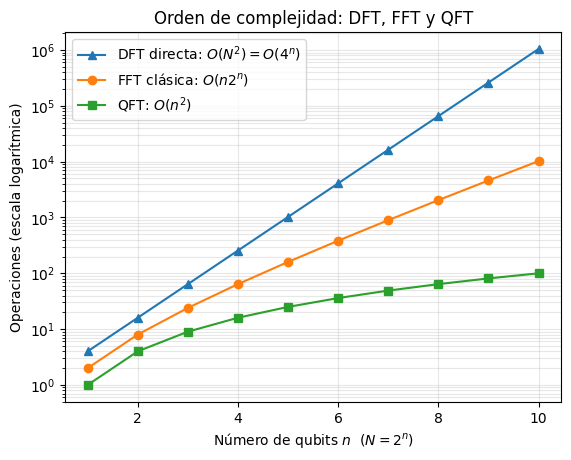

In [32]:
import numpy as np
import matplotlib.pyplot as plt

n_vals = np.arange(1, 11)                         # número de qubits n (N = 2^n)

dft_directa = [4**n for n in n_vals]              # DFT por definición: O(N^2) = O(4^n)
fft_clasica = [n * 2**n for n in n_vals]          # FFT clásica:        O(N log N) = O(n 2^n)
qft_cuantica = [n**2 for n in n_vals]             # QFT (circuito):     O(n^2) = O(log^2 N)

plt.semilogy(n_vals, dft_directa, marker='^', label="DFT directa: $O(N^2)=O(4^n)$")
plt.semilogy(n_vals, fft_clasica, marker='o', label="FFT clásica: $O(n2^n)$")
plt.semilogy(n_vals, qft_cuantica, marker='s', label="QFT: $O(n^2)$")

plt.title("Orden de complejidad: DFT, FFT y QFT")
plt.xlabel("Número de qubits $n$  ($N=2^n$)")
plt.ylabel("Operaciones (escala logarítmica)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Matriz de la $QFT$

Intentemos encontrar la matriz correspondiente a la $QFT$. Dado $\vec{x}$, las entradas del vector $\vec{y}$ correspondientes a su $QFT$, están dadas por

$$
y_k=\frac{1}{\sqrt{N}} \sum_{j=0}^{N-1}{\large e}^{\huge\frac{2\pi i j k }{N}}x_j = \frac{1}{\sqrt{N}} \sum_{j=0}^{N-1}\omega^{j k}x_j
$$

Por lo tanto, podemos escribir de forma equivalente:

\begin{align*}
y_0 &= \frac{1}{\sqrt{N}} \left (x_0 + x_1 + x_2 + \cdots + x_{N-1}  \right ) \\
y_1 &= \frac{1}{\sqrt{N}} \left (x_0 + x_1\omega  + x_2 \omega^2+ \cdots + x_{N-1} \omega^{N-1}  \right )\\
y_2 &= \frac{1}{\sqrt{N}} \left (x_0 + x_1\omega^2  + x_2 \omega^4+ \cdots + x_{N-1} \omega^{2N-2}  \right )\\
\vdots \\
y_{N-1} &= \frac{1}{\sqrt{N}} \left (x_0 + x_1\omega^{N-1}  + x_2 \omega^{2N-2}+ \cdots + x_{N-1} \omega^{(N-1)(N-1)}  \right )
\end{align*}

A partir de lo anterior, podemos ver que la $QFT$ es una transformación con la siguiente representación matricial:

$$QFT =  \frac{1}{\sqrt{N}} \pmatrix{1 & 1 & 1 &1  & \cdots & 1 \\ 1 & \omega & \omega^2 & \omega^3 & \cdots& \omega^{N-1} \\ 1 & \omega^2 &\omega^4 & \omega^6  & \cdots& \omega^{2N-2} \\ 1 & \omega^3 & \omega^6 & \omega^9 & \cdots& \omega^{3N-3} \\ \vdots &  \vdots &  \vdots &  \vdots &  \ddots &  \vdots \\ 1 & \omega^{N-1} & \omega^{2N-2} & \omega^{3N-3} & \cdots& \omega^{(N-1)(N-1)}}$$

donde $ \omega = {\large e}^{\huge\frac{2\pi i}{N}} $. Es una matriz de tamaño $N\times N$.

El renglón (o columna) $(j+1)$-ésimo tiene los elementos:

$$\left(\omega^j\right)^0\quad\left(\omega^j\right)^1\quad\left(\omega^j\right)^2\quad\cdots\quad\left(\omega^j\right)^{N-1}$$

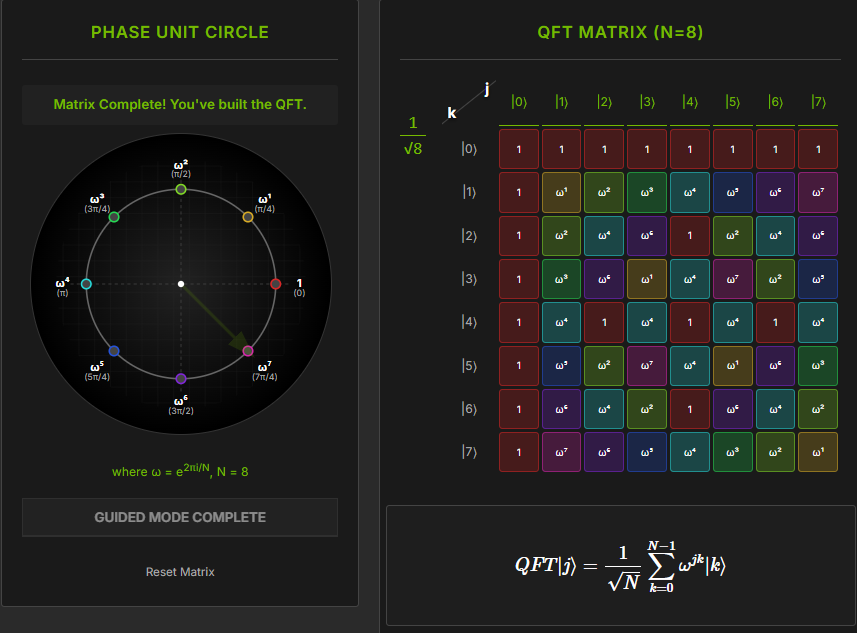

Por lo tanto, para un estado base $\ket{j}$ representado por el vector $\pmatrix{x_0~x_1\dots~x_{N-1}}^T$ donde $x_j=1$ y el resto de las entradas son $0$, su $QFT$ está dada por

$$
QFT\ket{j}=\frac{1}{\sqrt{N}} \sum_{k=0}^{N-1}{\large e}^{\huge\frac{2\pi i j k }{N}} \ket{k} = \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1}{\omega^{ j k} } \ket{k}
$$

Alternativamente:

$$ \ket{j} =  \pmatrix{0 \\ \vdots \\ 0 \\ 1 \\ 0 \\ \vdots \\ 0}  \xrightarrow{QFT}
 \frac{1}{\sqrt{N}} \left(
     \omega^{0} \ket{0} + \omega^{j} \ket{1} + \omega^{2j}\ket{2} + \cdots + \omega^{j(N-1)} \ket{N-1}\right) = \frac{1}{\sqrt{N}} \pmatrix{ 1 \\ \omega^j \\ \omega^{2j} \\ \vdots \\ \omega^{j(N-1)} }
$$

Es decir, realizar la operación $QFT\ket{j}$ nos devuelve la $(j+1)$-ésima columna de la matriz $QFT$.

$$ $$

<div class="alert alert-block alert-info">
<strong>Ejemplo</strong>: Aplicar la $QFT$ al estado cuántico $\ket{\psi}=\alpha \ket{0} + \beta \ket{1}$.

$$ $$

El estado cuántico $\ket{\psi}$ está representado por $\pmatrix{\alpha\\\beta}$ donde $x_0=\alpha$ y $x_1=\beta$.

$$ $$

Entonces,

$$y_0=\frac{1}{\sqrt{2}} \sum_{j=0}^{1}{\large e}^{\huge\frac{2\pi i j \cdot 0}{2}}x_j = \frac{ \alpha + \beta }{\sqrt{2}}$$

$$y_1=\frac{1}{\sqrt{2}} \sum_{j=0}^{1}{\large e}^{\huge\frac{2\pi i \cdot j \cdot 1}{2}}x_j = \frac{1}{\sqrt{2}} \biggl ({\large e}^{\huge\frac{2\pi i \cdot 0 \cdot 1}{2}}  x_0 + {\large e}^{\huge\frac{2\pi i\cdot 1\cdot 1}{2}}x_1 \biggr )=\frac{ \alpha - \beta }{\sqrt{2}}$$

Por lo tanto el nuevo estado es

$$QFT\ket{\psi}=\frac{\alpha+\beta}{\sqrt{2}} \ket{0} + \frac{\alpha-\beta}{\sqrt{2}} \ket{1}$$

De este ejercicio podemos concluir que aplicar $QFT$ a un solo qubit equivale a aplicarle la **compuerta Hadamard**.

Lo podemos comprobar tomando la matrix de la $QFT$ y $N=2$, entonces dicha matriz queda como:

$$QFT = \frac{1}{\sqrt{2}} \pmatrix{1 & 1 \\ 1 & \omega} = \frac{1}{\sqrt{2}} \pmatrix{1 & 1 \\ 1 & -1} = H$$

pues $\omega={\large e}^{\huge\frac{2\pi i}{2}}={\large e}^{\huge\pi i} = -1$

### Operador $QFT$

La $QFT$ es un operador unitario.

Su fila $(j+1)$-ésima es $\frac{1}{\sqrt{N}} \myvector {1 ~~ \omega^{j} ~~ \omega^{2j}~~~ \cdots ~~~ \omega^{jN-j}}$.

La magnitud de cada entrada es $1$, por lo que la longitud es $1$ $\left(=\dfrac{\overbrace{1+\cdots+1}^{N~~términos}}{N}\right)$.

La suma de los términos de la primera fila es $\dfrac{1}{\sqrt{N}}\overbrace{1+\cdots+1}^{N~~términos} = \sqrt{N}$.

La suma de los términos de cualquier otra fila es
$$ \dfrac{1}{\sqrt{N}} \left( 1 + \omega^j + \left(\omega^{j}\right)^2 + \cdots + \left(\omega^{j}\right)^{(N-1)}\right)
= \dfrac{1}{\sqrt{N}} \dfrac{1- \left( \omega^{j} \right)^N }{1-\omega^{j}} = \dfrac{1}{\sqrt{N}} \dfrac{ 1 - {\large e}^{\huge\frac{2 \pi i j N}{N}} }{1-\omega^{j}} = \dfrac{1}{\sqrt{N}} \dfrac{1-1}{1-\omega^{j}} = 0 $$

Esto usando la definición de la [serie geométrica](https://es.wikipedia.org/wiki/Serie_geom%C3%A9trica): $\sum_{k=0}^m ar^k=a\left(\dfrac{1-r^{m+1}}{1-r}\right)$.

$$ $$

Observemos que:
- el conjugado de $ \omega^{jk} $, denotado con $ \overline{\omega^{jk}} $, es igual a $ \omega^{-jk} $
- $ \omega^{j_1k} \cdot \omega^{j_2k} = \omega^{(j_1+j_2)k} $
- $ \overline{ \omega^{j_1k} } \cdot \omega^{j_2k} = \omega^{(j_2-j_1)k} $

El producto interno de la fila $(j_1+1)$-ésima y la fila $(j_2+1)$-ésima ($ j_1 < j_2 $) es la suma de las entradas de la fila $(j+1)$-ésima:

$$ 1 + \omega^j + \omega^{2j}+\cdots+\omega^{(N-1)j} = 0 $$

donde $ j = j_2 - j_1 $.

Por lo tanto, las filas (columnas) de la matriz $QFT$ forman un **conjunto ortonormal**.

### Desplazamiento lineal

El desplazamiento lineal de un vector de estado provoca un desplazamiento de fase relativo de su $QFT$. Lo contrario también es cierto.

Si $QFT$ $\pmatrix{\alpha_0 \\ \alpha_1 \\ \vdots \\ \alpha_{N-1} } = \pmatrix{\beta_0 \\ \beta_1 \\ \vdots \\ \beta_{N-1}}$, entonces $QFT$ $\pmatrix{\alpha_{N-1} \\ \alpha_0 \\ \vdots \\ \alpha_{N-2} } = \pmatrix{\beta_0 \\ \omega \beta_1 \\ \vdots \\ \omega^{N-1}\beta_{N-1}}$ y $QFT$  $\pmatrix{\alpha_0 \\ \omega  \alpha_1 \\ \vdots \\ \omega^{N-1}\alpha_{N-1} } = \pmatrix{\beta_1 \\ \beta_2 \\ \vdots \\ \beta_{0}}$.

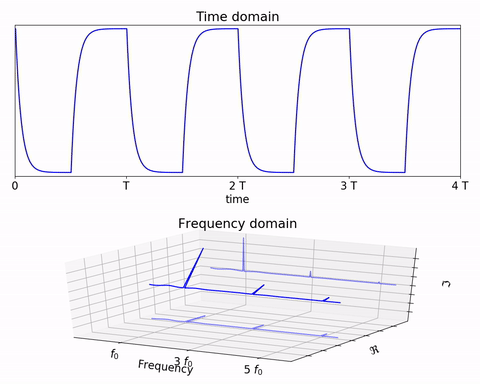
<p align="center"><em>Desplazamiento de una señal y su efecto sobre las fases de la Transformada de Fourier.</em></p>

<a id="2.3"></a>
## 2.3. Implementación del Circuito

<div class="alert alert-block alert-success">
<strong>Recordatorio</strong>: Expansión binaria de números

$$9=1(2^3)+0(2^2)+0(2^1)+1(2^0)\equiv_2 1001$$

$$0.75=\frac{1}{2}+\frac{1}{4}=1(2^{-1})+1(2^{-2})\equiv_2 0.11$$

$$\Rightarrow 9.75\equiv_2 1001.11$$

Multiplicando por $2$, tenemos

\begin{align*}
2(1001.11)&\equiv_{10} 1(2^3)2+0(2^2)2+0(2^1)2+1(2^0)2 \, + \, 1(2^{-1})2+1(2^{-2})2\\
&= \, \, \, \, \, 1(2^4)+0(2^3)+0(2^2)+1(2^1) \, + \, 1(2^{0})+1(2^{-1})\\
&\equiv_{2} 10011.1
\end{align*}

Es decir, el punto se recorrió una posición.

Recordemos que, tras aplicar $QFT$ al estado $\ket{\psi}=\alpha\ket{0} + \beta \ket{1}$, obtenemos $\frac{\alpha+\beta}{\sqrt{2}} \ket{0} + \frac{\alpha-\beta}{\sqrt{2}} \ket{1}$, que es el estado obtenido al aplicar Hadamard al estado $\ket{\psi}$.

Por lo tanto, el efecto de aplicar la $QFT$ a un solo qubit es equivalente a aplicar Hadamard.

Ahora veamos el efecto de aplicar $QFT$ a un sistema de $n$-qubits. Sea $N=2^n$.

Sea $\ket{j}$ un estado base, es decir, un estado del conjunto: $ \{ \ket{0},\ldots,\ket{N-1} \} $.

Podemos expresar $ \ket{j} = \ket{j_1 j_2 \cdots j_n } = \ket{j_1} \otimes \ket{j_2} \otimes \cdots \otimes \ket{j_n}$, donde $ (j_1 j_2 \cdots j_n) $ es la representación binaria de $n$ dígitos de $ j $:

\begin{array}{rcl}
  j & = &  j_1 2^{n-1} + j_2 2^{n-2} + \cdots + j_n 2^0 \\
  j & = & 2^n \sum\limits_{l=1}^n 2^{-l} j_l \\
  j & = & 2^{n}(0.j_1 j_2 \cdots j_n) \\
  \dfrac{j}{N} &= & 0.j_1 j_2 \cdots j_n
\end{array}

### Transformación de $ \ket{j} $

Sabemos que $ QFT \ket{j} $ da la $ (j+1) $-ésima columna:

$$ \ket{j} = \pmatrix{0 \\ \vdots \\ 0 \\ 1 \\ 0 \\ \vdots \\ 0} \xrightarrow{QFT}
\frac{1}{\sqrt{N}} \left(
\omega^{0} \ket{0} + \omega^{j} \ket{1} + \omega^{2j}\ket{2} + \cdots + \omega^{j(N-1)} \ket{N-1}
\right) = \frac{1}{\sqrt{N}}
\pmatrix{ 1 \\ \omega^j \\ \omega^{2j} \\ \vdots \\ \omega^{j(N-1)} } = \ket{u_j}
$$

El término $(k+1)$-ésimo de esta sumatoria es $ \omega^{j\cdot k} \ket{k} = \omega^{j\cdot k} \ket{k_1k_2\cdots k_n}. $

### Representación concisa para 5 qubits

Por ejemplo, tomemos $n = 5$, por lo que $N = 32$.

$$ \ket{j} \xrightarrow{QFT} \dfrac{1}{\sqrt{32}} \left( \omega^0 \ket{0} + \omega^j \ket{1} + \omega^{2j} \ket{2} + \cdots + \omega^{31j} \ket{ 31 } \right)$$

Sea $k = 13$. Entonces, el decimocuarto término de esta suma es $\dfrac{\omega^{j\cdot 13}}{\sqrt{32}} \ket{01101}$, donde $ 13 = 2^3 + 2^2+ 2^0 $.

Descomponemos $ \dfrac{\omega^{j\cdot 13}}{\sqrt{32}} \ket{01101} $ como $ \dfrac{1}{\sqrt{32}} \left(\ket{0} \otimes \omega^{j2^{\huge 3}}\ket{1} \otimes \omega^{j2^{\huge 2}} \ket{1} \otimes \ket{0} \otimes \omega^{j2^{\huge 0}} \ket{1}\right)$, donde:
- la amplitud de cada $ \ket{0} $ es $1$, y,
- $ \omega^{j\cdot 13} $ se distribuye entre los estados $ \ket{1} $ con base en $ 13 = 2^3 + 2^2 + 2^0 $.

Como cada número tiene una representación binaria única de cinco dígitos, podemos identificar de manera única los términos de la suma mediante esta descomposición.

Para $ k= 23 = 2^4 + 2^2 + 2^1 + 2^ 0 $, el término $24^{\circ}$ es $ \dfrac{1}{\sqrt{32}} \left(\omega^{j2^{\huge 4}} \ket{1} \otimes \ket{0} \otimes \omega^{j2^{\huge 2}} \ket{1} \otimes \omega^{j2^{\huge 1}} \ket{1} \otimes \omega^{j2^{\huge 0}} \ket{1}\right)$.

De esta manera, podemos descomponer cada término de forma única:
- Para el 1er dígito, un término tiene ya sea $ \ket{0} $ ó $ \omega^{j2^{\huge 4}} \ket{1} $.
- Para el 2do dígito, tiene ya sea $ \ket{0} $ ó $ \omega^{j2^{\huge 3}} \ket{1} $.
- Para el 3er dígito, tiene ya sea $ \ket{0} $ ó $ \omega^{j2^{\huge 2}} \ket{1} $.
- Para el 4to dígito, tiene ya sea $ \ket{0} $ ó $ \omega^{j2^{\huge 1}} \ket{1} $.
- Para el 5to dígito, tiene ya sea $ \ket{0} $ ó $ \omega^{j2^{\huge 0}} \ket{1} $.

Entonces, podemos poner la suma completa

$$ \dfrac{1}{\sqrt{32}} \left( \omega^0 \ket{0} + \omega^j \ket{1} + \omega^{2j} \ket{2} + \cdots + \omega^{31j} \ket{ 31 } \right)$$

en esta forma concisa

$$
\dfrac{1}{\sqrt{32}}\;
 \underbrace{ \left(\ket{0} + \omega^{j2^{\huge 4}} \ket{1}\right)}_{1er~dígito} \otimes
 \underbrace{ \left(\ket{0} + \omega^{j2^{\huge 3}} \ket{1}\right)}_{2do~dígito} \otimes
 \underbrace{ \left(\ket{0} + \omega^{j2^{\huge 2}} \ket{1}\right)}_{3er~dígito} \otimes
 \underbrace{ \left(\ket{0} + \omega^{j2^{\huge 1}} \ket{1}\right)}_{4to~dígito} \otimes
 \underbrace{ \left(\ket{0} + \omega^{j2^{\huge 0}} \ket{1}\right)}_{5to~dígito} $$

Al tomar una componente de cada paréntesis, obtenemos todos los términos de la suma; es decir, hay cinco paréntesis, y por lo tanto, $ 2^5 = 32 $ términos diferentes.

### Representación concisa para $n$ qubits

La representación concisa presentada para $ n=5 $ es válida para cualquier número entero positivo $ n $.

$$ QFT\ket{j} = \dfrac{1}{\sqrt{N}}\;
 \underbrace{ \left( \ket{0}+\omega^{j2^{\huge n-1}} \ket{1} \right) }_{1er~dígito} \otimes
 \underbrace{ \left(\ket{0}+\omega^{j2^{\huge n-2}} \ket{1} \right) }_{2do~dígito} \otimes
 \cdots \otimes
 \underbrace{ \left(\ket{0}+\omega^{j2^{\huge 0}} \ket{1} \right) }_{enésimo ~ dígito}$$

En esta representación concisa, examinamos detenidamente las fases relativas: $ \{ \omega^{j2^{\huge t}} \mid 0 \leq t < n \} $.

Comenzamos con la primera fase relativa:
$$ {\large\omega}^{\huge j2^{\huge n-1}} =
{\large e}^{\huge\left( \frac{2\pi i}{N}\cdot j \cdot 2^{n-1} \right)}
= {\large e}^{\large\left( 2\pi i \cdot \frac{j}{N} \cdot 2^{n-1} \right)}
$$

El exponente es $ 2\pi i \cdot \mathbf{\frac{j}{N}} \cdot 2^{n-1} $.

Recordemos que $ \dfrac{j}{N} = 0.j_1 j_2 \cdots j_n$ . Entonces, el exponente es $ 2\pi i \cdot \mathbf{ [0.j_1 j_2 \cdots j_n] } \cdot 2^{n-1} $.

Tomemos en cuenta que multiplicar $ [0.j_1 j_2 \cdots j_n] $ por $2$ desplaza el punto decimal un dígito a la derecha:

$$ 2 \cdot [0.j_1 j_2 \cdots j_n] = [j_1 . j_2 \cdots j_n] $$

Por lo tanto, si lo multiplicamos por $ 2^{n-1} $, el punto decimal se desplaza $ (n-1) $ dígitos a la derecha:

$$ 2^{n-1} \cdot [ 0.j_1 j_2 \cdots j_n ] = \mathbf{ [ j_1 j_2 \cdots j_{n-1} . j_n ] } $$

Para cualquier entero positivo $ m $, $ e^{2\pi i \cdot m } $ es igual a $ e^{2 \pi i} $. _El valor de cualquier ángulo no cambia al desplazarse $ 2 \pi $._

Por lo tanto, el exponente se simplifica como $ 2\pi i \cdot \mathbf{ [0.j_n] } $ eliminando la parte entera de $ \mathbf{ [ j_1 j_2 \cdots j_{n-1} . j_n ] } $.

Del mismo modo, podemos simplificar todas las fases relativas excepto la última:

$$ QFT\ket{j} = \dfrac{1}{\sqrt{N}}
 \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_n ]} } \ket{1} \right) \otimes
 \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_{n-1}j_n ]} } \ket{1} \right) \otimes
 \cdots \otimes
 \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]} } \ket{1} \right)
$$

<div class="alert alert-block alert-success">
<strong>Recordatorio</strong>: La exponencial elevada a $2\pi i$

Tenemos que

$${\large e}^{\large 2\pi i} = 1$$

Sucede lo mismo para los múltiplos de $2\pi i$, es decir,

$${\large e}^{\large m2\pi i} = 1^{\large m}=1$$


### Diseño del circuito

Al diseñar el circuito, se considera el estado en orden inverso:

$$\dfrac{1}{\sqrt{N}}\; \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]} } \ket{1} \right)}_{q_1} \otimes \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_2\cdots j_n]} } \ket{1} \right)}_{q_2} \otimes \cdots  \otimes \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_{n-1}j_n]} } \ket{1} \right)}_{q_{n-1}} \otimes \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_n]} } \ket{1} \right)}_{q_n}$$

Después de tener esto, revertiremos el resultado utilizando operadores $SWAP$.

#### El primer qubit

Establecemos el estado de $ q_1 $ en $ \dfrac{1}{\sqrt{2}}\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]}} \ket{1} \right) $ aplicando $ n $ compuertas:

$ \ket{j_1} \xrightarrow{n~~compuertas} \dfrac{1}{\sqrt{2}}\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]} } \ket{1} \right)$

Comenzamos aplicando una compuerta Hadamard a $ q_1 $:
- Si $ q_1 $ está en $ \ket{0} $, entonces su estado se establece en $ \ket{+} = \frac{1}{\sqrt{2}} \left( \ket{0} + \ket{1} \right) $.
- Si $ q_1 $ está en $ \ket{1} $, entonces su estado se establece en $ \ket{-} = \frac{1}{\sqrt{2}} \left( \ket{0} - \ket{1} \right) $.

Aquí, la fase relativa es la siguiente:
- En el primer caso, la amplitud de $ \ket{1} $ es
  $$ 1 = {\large e}^{\large 2 \pi i \cdot \mathbf{1}} = {\large e}^{\large 2 \pi i \cdot \mathbf{[0.0]} } $$
- En el segundo caso, la amplitud de $ \ket{1} $ es
  $$ -1 = {\large e}^{\large 2 \pi i \cdot \mathbf{\frac{1}{2}}} = {\large e}^{\large 2 \pi i \cdot \mathbf{[0.1]} } $$

En resumen, la fase relativa en este punto es $ {\large e}^{\large 2 \pi i \cdot \mathbf{[0.j_1]} } $.

Observemos que $ j_1 $ aparece en la fracción binaria del exponente. Ahora, establecemos la fracción binaria en $ \mathbf{[0.j_1j_2]} $.
- Si $ j_2 $ es $0$, no hacemos nada (se suma cero).
- Si $ j_2 $ es $1$, entonces $ \dfrac{1}{4} $ debe sumarse a la fracción binaria. Para esto, aplicamos la compuerta de fase $ R_m $ a $ q_1 $ para $ m = 2 $.

$$ R_m = \pmatrix{1 & 0 \\ 0 & {\large e}^{\huge \frac{2 \pi i}{2^m}}} $$

Para abordar ambos casos, aplicamos $ R_2 $ a $ q_1 $, controlado por $ q_2 $:
$ CR_m $ para $ m = 2 $.

$$ CR_m = \pmatrix{ 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & {\large e}^{ \huge \frac{ 2\pi i}{2^m} } }  $$

De forma similar, para establecer la fracción binaria en $ \mathbf{[0.j_1j_2j_3]} $, aplicamos la compuerta de fase $ R_3 $ a $ q_1 $, controlado por $ q_3 $.

Hacemos lo mismo para $ j_4,\ldots,j_n $, y aplicamos $ R_4,\ldots,R_n $ a $ q_1 $, controlado por $ q_4,\ldots,q_n $, respectivamente.

#### El segundo qubit

Comenzamos aplicando una compuerta Hadamard a \(q_2\), estableciendo una fase relativa de ${\large e}^{\large 2 \pi i \cdot \mathbf{[0.j_2]}}$.

Luego, para $j_3,\ldots,j_n$, aplicamos $R_2,\ldots,R_{n-1}$ a $q_2$, controlados por $q_3,\ldots,q_n$, respectivamente.

Por lo tanto, el estado de $q_2$ se establece en ${\large e}^{\large 2 \pi i \cdot \mathbf{[0.j_2\cdots j_n]}}$.

#### Resto de qubits

Utilizamos el mismo procedimiento iterativamente para los qubits $ q_3, \ldots, q_n $.

En cada iteración, aplicamos una compuerta de fase controlada menos y no aplicamos ninguna compuerta de fase a $ q_n $.

Por lo tanto, al final de la iteración, el estado del circuito se establece en

$$ \dfrac{1}{\sqrt{N}}\;
 \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]} } \ket{1} \right)}_{q_1} \otimes
 \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_2\cdots j_n]} } \ket{1} \right)}_{q_2} \otimes
 \cdots \otimes
 \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_{n-1}j_n]} } \ket{1} \right)}_{q_{n-1}} \otimes
 \underbrace{\left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_n]} } \ket{1} \right)}_{q_n}
$$

### Swapping

El estado final deseado es

$$ QFT\ket{j} = \dfrac{1}{\sqrt{N}}  
    \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_n ]} } \ket{1} \right) \otimes  
    \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_{n-1}j_n ]} } \ket{1} \right) \otimes
    \cdots  \otimes
    \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]} } \ket{1} \right)
$$

Por lo tanto, aplicamos compuertas $SWAP$ en $ [q_1,q_n], [q_2,q_{n-1}], [q_3,q_{n-2}]$, y así sucesivamente.

### El circuito general

De este modo, el circuito cuántico que implementa la $QFT$ es como sigue:

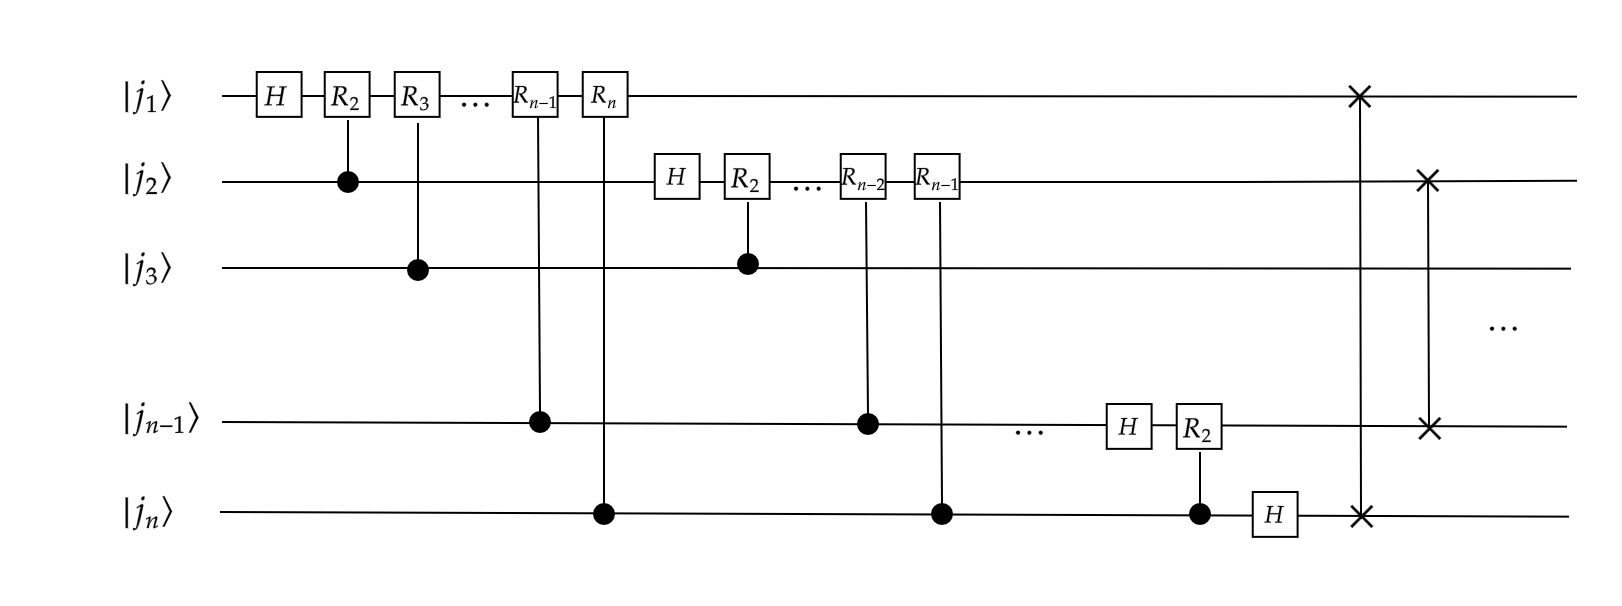

<a id="2.4"></a>
## 2.4. Implementación en Qiskit

En Qiskit podemos usar la siguiente compuerta incluida en el paquete principal:

$$CPhaseGate(\lambda) = \pmatrix{ 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & {\large e}^{ \large i\lambda } }$$

La cual puede ser aplicada a un objeto `QuantumCircuit` con el método `cp()`.

In [33]:
from qiskit import QuantumCircuit
import numpy as np

def miQFT(n):
    qft_circuit = QuantumCircuit(n)
    for j in reversed(range(n)):                  # considerar el orden invertido de qubits en Qiskit
        qft_circuit.h(j)
        for k in reversed(range(j)):
            qft_circuit.cp(np.pi / 2**(j-k), k, j)
        qft_circuit.barrier()
    for i in range(n//2):
        qft_circuit.swap(i, n-i-1)
    return qft_circuit

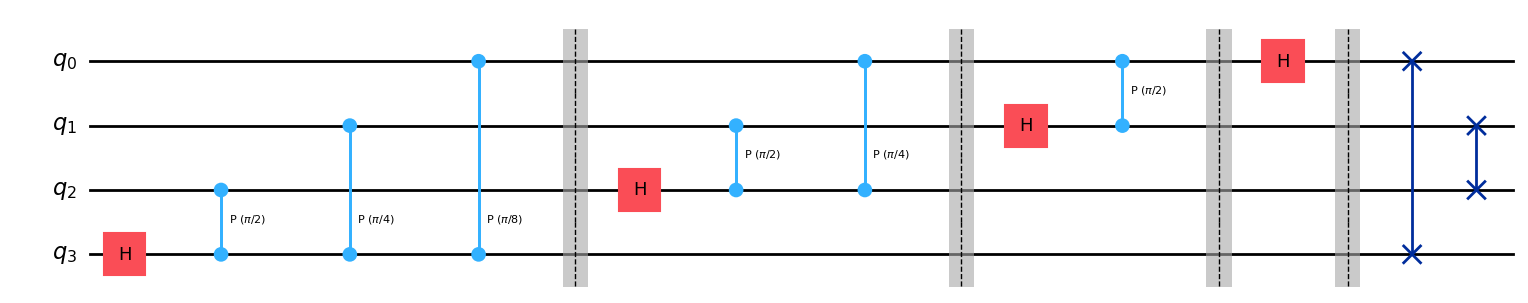

In [34]:
mi_qft_qc4 = miQFT(4)
mi_qft_qc4.draw('mpl')

Qiskit ya cuenta con una clase llamada `QFT` que permite crear este circuito:

/tmp/ipykernel_1226/3236764561.py:3: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft_qc4 = QFT(4, insert_barriers=True)


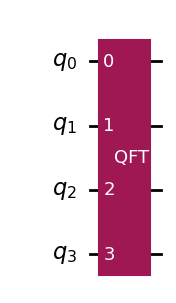

In [35]:
from qiskit.circuit.library import QFT

qft_qc4 = QFT(4, insert_barriers=True)
qft_qc4.draw('mpl')

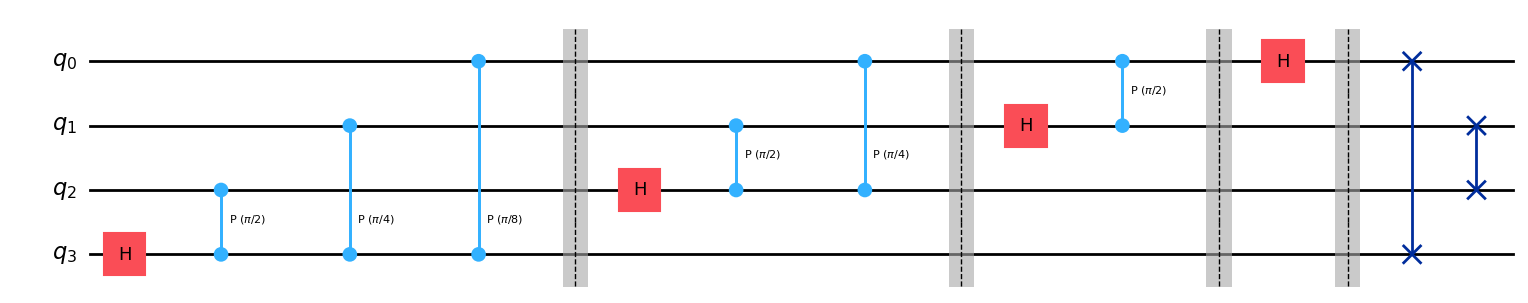

In [36]:
qft_qc4.decompose().draw('mpl')

<a id="2.4.1"></a>
## 2.4.1. Histogramas de la Transformada Cuántica de Fourier

Una vez implementado el circuito de la QFT, podemos analizar sus resultados mediante histogramas de probabilidad.

Estos histogramas muestran la probabilidad de obtener cada estado de la base computacional al realizar una medición. Para observar su comportamiento, aplicaremos la QFT a diferentes estados iniciales y compararemos los resultados obtenidos.


### Ejemplo 1: Aplicar la QFT al estado $\ket{0000}$

Consideremos un sistema de 4 qubits cuyo estado inicial es $\ket{0000}$. Al aplicar la QFT, obtenemos una superposición uniforme de todos los estados de la base computacional.

Recordemos que la QFT está definida por

$$
QFT|j\rangle=\frac{1}{\sqrt{N}}\sum_{k=0}^{N-1}e^{\frac{2\pi ijk}{N}}\ket{k}
$$

Para $j=0$ y $N=2^4=16$, tenemos

$$
QFT|0\rangle=\frac{1}{4}\sum_{k=0}^{15}\ket{k}
$$

Por lo tanto, la probabilidad de medir cualquiera de los 16 estados es

$$
P(k)=\left|\frac{1}{4}\right|^2=\frac{1}{16}=0.0625
$$

Es decir, todos los estados tienen la misma probabilidad de ser medidos.


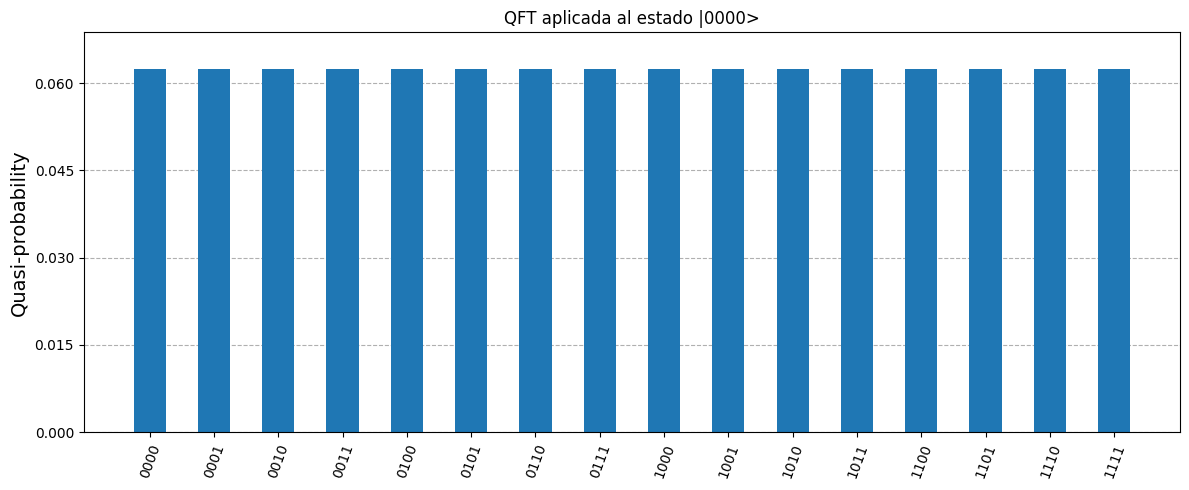

In [37]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

# Creamos un circuito de 4 qubits
qc = QuantumCircuit(4)

# Aplicamos la QFT al estado inicial |0000>
qc.compose(miQFT(4), inplace=True)

# Calculamos las probabilidades de cada estado
estado_final = Statevector.from_instruction(qc)
probabilidades = estado_final.probabilities_dict()

# Graficamos el histograma
plot_histogram(
    probabilidades,
    title="QFT aplicada al estado |0000>",
    figsize=(12, 5),
    bar_labels=False
)


**Interpretación de los resultados**

Observamos que los 16 estados de la base computacional tienen la misma probabilidad de medición, igual a $0.0625$.

Esto ocurre porque la QFT aplicada al estado $\ket{0000}$ genera una superposición uniforme, donde todas las amplitudes tienen el mismo valor.

Por lo tanto, al realizar una medición, cualquiera de los 16 estados puede obtenerse con la misma probabilidad.


### Ejemplo 2: Aplicar la QFT al estado $\ket{0001}$

Consideremos un sistema de 4 qubits cuyo estado inicial es $\ket{0001}$. Al aplicar la QFT, obtenemos una superposición de todos los estados de la base computacional, pero con diferentes fases relativas.

Recordemos que la QFT está definida por

$$
QFT|j\rangle=\frac{1}{\sqrt{N}}\sum_{k=0}^{N-1}e^{\frac{2\pi ijk}{N}}\ket{k}
$$

Para $j=1$ y $N=2^4=16$, tenemos

$$
QFT|1\rangle=\frac{1}{4}\sum_{k=0}^{15}e^{\frac{2\pi ik}{16}}\ket{k}
$$

Observemos que las amplitudes contienen un factor exponencial complejo que depende de $k$. Sin embargo, la magnitud de este factor exponencial es siempre igual a 1.

Por lo tanto, la probabilidad de medir cualquiera de los 16 estados es

$$
P(k)=\left|\frac{1}{4}e^{\frac{2\pi ik}{16}}\right|^2=\frac{1}{16}=0.0625
$$

Es decir, aunque las amplitudes tienen diferentes fases relativas, todos los estados conservan la misma probabilidad de ser medidos.


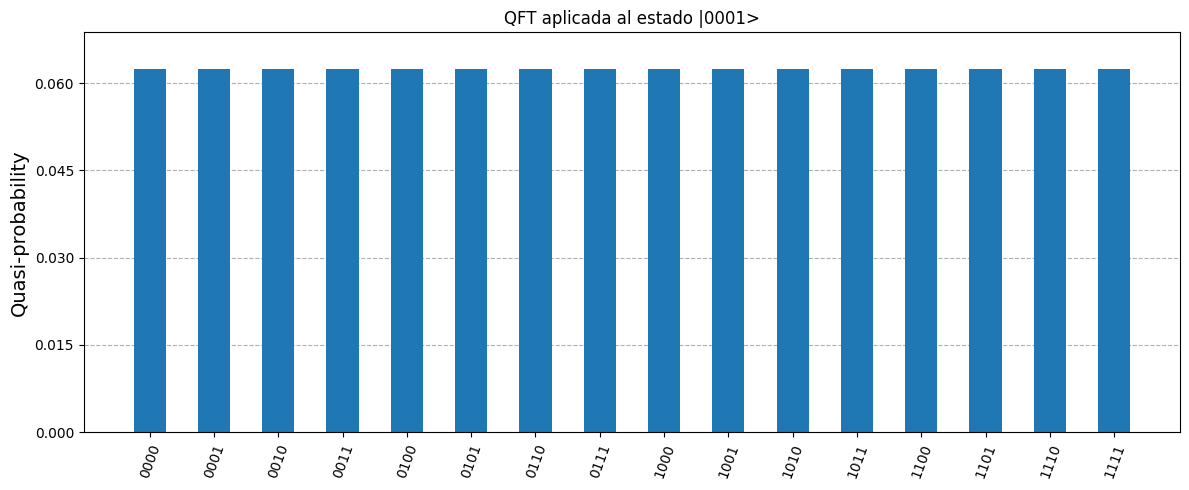

In [38]:
# Creamos un circuito de 4 qubits
qc = QuantumCircuit(4)

# Preparamos el estado inicial |0001>
qc.x(0)

# Aplicamos la QFT
qc.compose(miQFT(4), inplace=True)

# Calculamos las probabilidades de cada estado
estado_final = Statevector.from_instruction(qc)
probabilidades = estado_final.probabilities_dict()

# Graficamos el histograma
plot_histogram(
    probabilidades,
    title="QFT aplicada al estado |0001>",
    figsize=(12, 5),
    bar_labels=False
)


**Interpretación de los resultados**

Observamos que los 16 estados de la base computacional tienen la misma probabilidad de medición, igual a $0.0625$.

Aunque el histograma es igual al obtenido para el estado $\ket{0000}$, los estados cuánticos resultantes son diferentes, ya que en este caso las amplitudes presentan distintas fases relativas.

Esto nos muestra que los histogramas de probabilidad no permiten observar directamente las fases de un estado cuántico.


### Ejemplo 3: Aplicar la QFT a una superposición de estados

Consideremos un sistema de 4 qubits cuyo estado inicial es

$$
\ket{\psi}=\frac{1}{\sqrt{2}}(|0000\rangle+|0001\rangle)
$$

A diferencia de los ejemplos anteriores, ahora aplicaremos la QFT a una superposición de dos estados de la base computacional.

Recordemos que la QFT es una transformación lineal, por lo que

$$
QFT\ket{\psi}=\frac{1}{\sqrt{2}}(QFT\ket{0}+QFT\ket{1})
$$

Utilizando la definición de la QFT para $N=2^4=16$, tenemos

$$
QFT|0\rangle=\frac{1}{4}\sum_{k=0}^{15}\ket{k}
$$

$$
QFT\ket{1}=\frac{1}{4}\sum_{k=0}^{15}e^{\frac{2\pi ik}{16}}\ket{k}
$$

Por lo tanto, el estado resultante es

$$
QFT\ket{\psi}=\frac{1}{4\sqrt{2}}\sum_{k=0}^{15}\left(1+e^{\frac{2\pi ik}{16}}\right)\ket{k}
$$

Observemos que las amplitudes dependen de la suma de dos términos complejos, por lo que pueden interferir de manera constructiva o destructiva.

Para calcular la probabilidad de medir un estado $\ket{k}$, obtenemos

$$
P(k)=\left|\frac{1}{4\sqrt{2}}\left(1+e^{\frac{2\pi ik}{16}}\right)\right|^2
$$

Utilizando la identidad

$$
|1+e^{i\theta}|^2=2+2\cos(\theta)
$$

obtenemos

$$
P(k)=\frac{1}{16}\left(1+\cos\left(\frac{2\pi k}{16}\right)\right)
$$

Por lo tanto, las probabilidades de medición dependen del valor de $k$, a diferencia de los ejemplos anteriores.

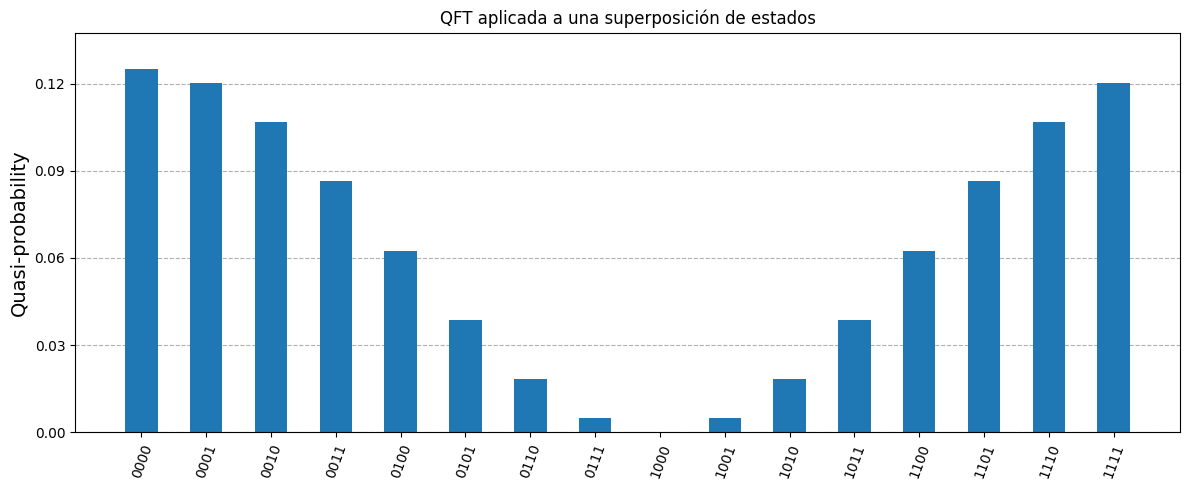

In [39]:
# Creamos un circuito de 4 qubits
qc = QuantumCircuit(4)

# Preparamos el estado inicial (|0000> + |0001>)/sqrt(2)
qc.h(0)

# Aplicamos la QFT
qc.compose(miQFT(4), inplace=True)

# Calculamos las probabilidades de cada estado
estado_final = Statevector.from_instruction(qc)
probabilidades = estado_final.probabilities_dict()

# Graficamos el histograma
plot_histogram(
    probabilidades,
    title="QFT aplicada a una superposición de estados",
    figsize=(12, 5),
    bar_labels=False
)


### Interpretación de los resultados

Observamos que, a diferencia de los ejemplos anteriores, los 16 estados de la base computacional ya no tienen la misma probabilidad de medición.

Esto ocurre porque la QFT aplicada a una superposición de estados produce interferencia entre sus amplitudes.

En algunos estados, las amplitudes interfieren constructivamente, aumentando su probabilidad de medición. En otros, interfieren destructivamente, disminuyendo dicha probabilidad.

Por ejemplo, el estado $\ket{0000}$ tiene una probabilidad de $0.125$, mientras que la probabilidad del estado $\ket{1000}$ es cero.

Por lo tanto, este ejemplo muestra cómo la QFT puede transformar las fases relativas de una superposición en diferencias en las probabilidades de medición.

### Ejemplo 4: Aplicar la QFT a una superposición uniforme

Consideremos un sistema de 4 qubits cuyo estado inicial es una superposición uniforme de todos los estados de la base computacional:

$$
\ket{\psi}=\frac{1}{4}\sum_{j=0}^{15}\ket{j}
$$

A diferencia de los ejemplos anteriores, ahora aplicaremos la QFT a una superposición de los 16 estados de la base computacional, todos con la misma amplitud.

Recordemos que la QFT está definida por

$$
QFT\ket{j}=\frac{1}{\sqrt{N}}\sum_{k=0}^{N-1}e^{\frac{2\pi ijk}{N}}\ket{k}
$$

Para $N=2^4=16$, tenemos

$$
QFT\ket{\psi}=\frac{1}{4}\sum_{j=0}^{15}QFT\ket{j}
$$

Sustituyendo la definición de la QFT, obtenemos

$$
QFT\ket{\psi}=\frac{1}{16}\sum_{j=0}^{15}\sum_{k=0}^{15}e^{\frac{2\pi ijk}{16}}\ket{k}
$$

Reordenando las sumatorias, tenemos

$$
QFT\ket{\psi}=\frac{1}{16}\sum_{k=0}^{15}\left(\sum_{j=0}^{15}e^{\frac{2\pi ijk}{16}}\right)\ket{k}
$$

Observemos que la sumatoria interior es una serie geométrica.

Para $k=0$, todos los términos son iguales a 1, por lo que

$$
\sum_{j=0}^{15}e^{\frac{2\pi ij(0)}{16}}=16
$$

Para $k=1,2,\ldots,15$, utilizando la fórmula de la serie geométrica, obtenemos

$$
\sum_{j=0}^{15}e^{\frac{2\pi ijk}{16}}=
\frac{1-e^{2\pi ik}}{1-e^{\frac{2\pi ik}{16}}}=0
$$

Esto ocurre porque $e^{2\pi ik}=1$ para cualquier entero $k$, mientras que el denominador es distinto de cero para $k=1,\ldots,15$.

Por lo tanto, el único término que permanece en la sumatoria es el correspondiente a $k=0$:

$$
QFT\ket{\psi}=\frac{16}{16}\ket{0}=\ket{0000}
$$

Así, la probabilidad de medir el estado $|0000\rangle$ es

$$
P(0)=|1|^2=1
$$

Mientras que, para los demás estados,

$$
P(k)=0,\qquad k=1,2,\ldots,15
$$

Por lo tanto, toda la probabilidad de medición se concentra en el estado $\ket{0000}$.

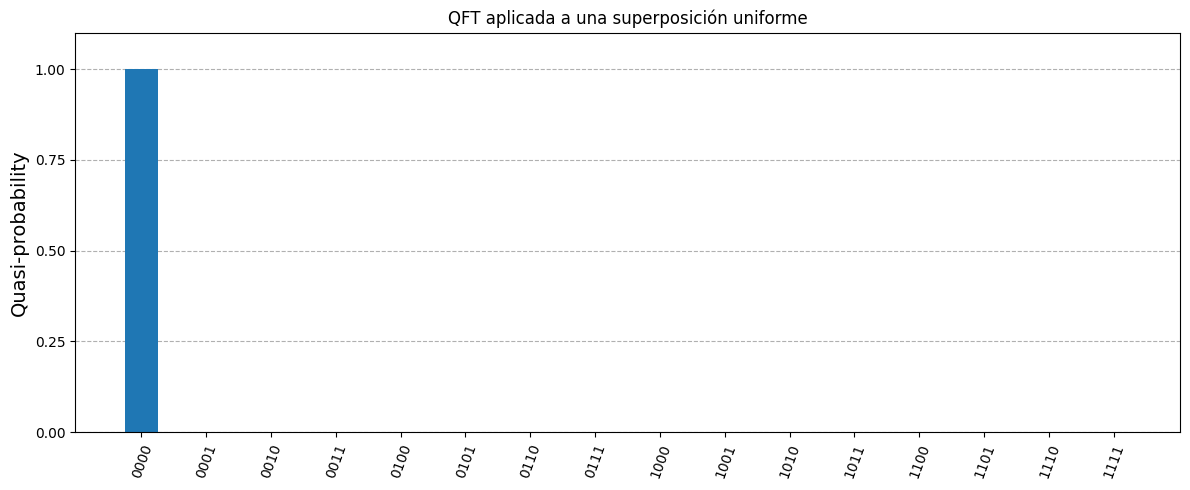

In [40]:
# Creamos un circuito de 4 qubits
qc = QuantumCircuit(4)

# Preparamos una superposición uniforme
for i in range(4):
    qc.h(i)

# Aplicamos la QFT
qc.compose(miQFT(4), inplace=True)

# Calculamos las probabilidades de cada estado
estado_final = Statevector.from_instruction(qc)
probabilidades = estado_final.probabilities_dict()

# Graficamos el histograma
plot_histogram(
    probabilidades,
    title="QFT aplicada a una superposición uniforme",
    figsize=(12, 5),
    bar_labels=False
)


### Interpretación de los resultados

Observamos que, a diferencia de los ejemplos anteriores, toda la probabilidad de medición se concentra en el estado $\ket{0000}$.

Esto ocurre porque, al aplicar la QFT a una superposición uniforme, las amplitudes interfieren constructivamente para el estado $\ket{0000}$ y destructivamente para los demás estados.

Por lo tanto, la probabilidad de medir $\ket{0000}$ es igual a 1, mientras que la probabilidad de medir cualquier otro estado es cero.

Este ejemplo muestra cómo la QFT puede transformar una superposición uniforme en un único estado de la base computacional mediante la interferencia de amplitudes.

### Ejemplo 5: Aplicar la QFT al estado de Bell $\ket{\beta_{00}}$

Usaremos el estado de Bell que ya vimos en la sección 2.2:

$$
\ket{\beta_{00}}=\frac{1}{\sqrt2}\left(\ket{00}+\ket{11}\right)
$$

Es un sistema de $n=2$ qubits, así que $N=2^2=4$ y $\omega=e^{2\pi i/4}=i$. Seguimos la convención de Qiskit del laboratorio: los estados se escriben $\ket{q_1q_0}$, con $q_0$ el bit menos significativo, de modo que $\ket{j}=\ket{q_1q_0}$ con $j=2q_1+q_0$:

$$
\ket{0}=\ket{00},\qquad \ket{1}=\ket{01},\qquad \ket{2}=\ket{10},\qquad \ket{3}=\ket{11}.
$$

En forma vectorial, $\vec{x}=\begin{pmatrix}\frac{1}{\sqrt2} & 0 & 0 & \frac{1}{\sqrt2}\end{pmatrix}^T$: solo $x_0$ y $x_3$ son distintos de cero.

#### Circuito y compuertas

El circuito de la QFT de $2$ qubits (el de `miQFT(2)`) aplica, en este orden:

1. $H$ sobre $q_1$.
2. $CP(\pi/2)$ con control $q_0$ y objetivo $q_1$ (es la rotación controlada $CR_2$ de la sección 2.3).
3. $H$ sobre $q_0$.
4. $SWAP$ entre $q_0$ y $q_1$.

(En la notación de 2.3, los qubits $q_1,q_2$ corresponden aquí a $q_1,q_0$.) Necesitaremos dos reglas.

**Hadamard.** Sobre un qubit, $H\ket{a}=\frac{1}{\sqrt2}\sum_{b=0}^{1}(-1)^{ab}\ket{b}$, por lo que

$$
H\left(c_0\ket{0}+c_1\ket{1}\right)=c_0'\ket{0}+c_1'\ket{1},\qquad c_0'=\frac{c_0+c_1}{\sqrt2},\quad c_1'=\frac{c_0-c_1}{\sqrt2}.
$$

La Hadamard **mezcla** amplitudes: las suma en $\ket{0}$ y las resta en $\ket{1}$. Si $c_0$ y $c_1$ tienen la misma fase, la suma refuerza (interferencia constructiva) y la resta se anula (destructiva); si difieren en fase, el reparto cambia. Así es como una **fase** se convierte en una diferencia de **amplitudes**.

**Fase controlada.** En la base $\ket{00},\ket{01},\ket{10},\ket{11}$,

$$
CP(\theta)=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&1&0\\0&0&0&e^{i\theta}\end{pmatrix},\qquad CP\left(\tfrac{\pi}{2}\right):\; e^{i\pi/2}=i .
$$

Solo multiplica por $e^{i\theta}$ la amplitud de $\ket{11}$. No cambia ningún módulo (ni las probabilidades) y, como la matriz es simétrica, control y objetivo son intercambiables.

#### Resultado esperado: cálculo directo con $F_4$

Como solo $x_0$ y $x_3$ son no nulos, $F_4\vec{x}$ es $\frac{1}{\sqrt2}$ veces la suma de las columnas $0$ y $3$ de $F_4$:

$$
F_4\vec{x}=\frac{1}{2}\cdot\frac{1}{\sqrt2}\begin{pmatrix}1&1&1&1\\1&i&-1&-i\\1&-1&1&-1\\1&-i&-1&i\end{pmatrix}\begin{pmatrix}1\\0\\0\\1\end{pmatrix}=\frac{1}{2\sqrt2}\begin{pmatrix}1+1\\1-i\\1-1\\1+i\end{pmatrix}=\frac{1}{2\sqrt2}\begin{pmatrix}2\\1-i\\0\\1+i\end{pmatrix}.
$$

Con $1-i=\sqrt2\,e^{-i\pi/4}$ y $1+i=\sqrt2\,e^{i\pi/4}$:

$$
QFT\ket{\beta_{00}}=\frac{1}{\sqrt2}\ket{00}+\frac12e^{-i\pi/4}\ket{01}+0\cdot\ket{10}+\frac12e^{i\pi/4}\ket{11}.
$$

Las probabilidades son $\left(\tfrac12,\tfrac14,0,\tfrac14\right)$, y suman $1$. Este es el estado que debe producir el circuito.

#### Evolución paso a paso

**Estado inicial.**

$$
\ket{\psi_0}=\frac{1}{\sqrt2}\left(\ket{00}+\ket{11}\right).
$$

Los módulos son $\frac{1}{\sqrt2}$ en $\ket{00}$ y $\ket{11}$ (probabilidad $\frac12$ cada uno) y las fases son $0$.

**Paso 1: $H$ sobre $q_1$.** Por linealidad actuamos sobre cada término, escribiendo $\ket{00}=\ket{0}_{q_1}\ket{0}_{q_0}$ y $\ket{11}=\ket{1}_{q_1}\ket{1}_{q_0}$:

$$
\begin{aligned}
\ket{00}&\longrightarrow\frac{\ket{0}+\ket{1}}{\sqrt2}\ket{0}=\frac{\ket{00}+\ket{10}}{\sqrt2},\\
\ket{11}&\longrightarrow\frac{\ket{0}-\ket{1}}{\sqrt2}\ket{1}=\frac{\ket{01}-\ket{11}}{\sqrt2}.
\end{aligned}
$$

Sumando, con el factor $\frac{1}{\sqrt2}$ del estado inicial:

$$
\ket{\psi_1}=\frac12\left(\ket{00}+\ket{01}+\ket{10}-\ket{11}\right).
$$

- **Amplitudes:** los dos términos de Bell se reparten en cuatro resultados equiprobables, todos con módulo $\frac12$ y probabilidad $\frac14$. No hay interferencia todavía, porque cada rama ocupa estados distintos ($\ket{00},\ket{10}$ la primera; $\ket{01},\ket{11}$ la segunda).
- **Fases:** todas valen $0$, salvo $\ket{11}$, que tiene fase $\pi$ (pues $-1=e^{i\pi}$). Ese signo viene de $H\ket{1}=\ket{-}$ y, en la notación de 2.3, es la fase $e^{2\pi i[0.j_1]}$ que la Hadamard escribe en $q_1$.

**Paso 2: $CP(\pi/2)$ (control $q_0$, objetivo $q_1$).** Solo $\ket{11}$ recibe el factor $i$, así que su amplitud pasa de $-\frac12$ a $-\frac{i}{2}$:

$$
\ket{\psi_2}=\frac12\left(\ket{00}+\ket{01}+\ket{10}-i\ket{11}\right).
$$

- **Amplitudes:** los módulos no cambian, por lo que las cuatro probabilidades siguen siendo $\frac14$. Una medición en la base computacional **no** distingue $\ket{\psi_1}$ de $\ket{\psi_2}$.
- **Fases:** la fase de $\ket{11}$ pasa de $\pi$ a $\pi+\frac{\pi}{2}=\frac{3\pi}{2}\equiv-\frac{\pi}{2}$. En la rama $\ket{11}$ de la entrada, $q_1$ queda en $\frac{1}{\sqrt2}\left(\ket{0}+e^{2\pi i[0.j_1j_0]}\ket{1}\right)$ con $[0.11]_2=\frac34$, es decir, con fase $e^{2\pi i\cdot 3/4}=-i$; en la rama $\ket{00}$ esa fase es $1$. La rotación controlada solo "se activa" donde $q_0=1$, y la información de fase todavía no es visible en las probabilidades.

**Paso 3: $H$ sobre $q_0$.** Agrupamos $\ket{\psi_2}$ según $q_1$:

$$
\ket{\psi_2}=\frac12\left[\ket{0}_{q_1}\left(\ket{0}+\ket{1}\right)_{q_0}+\ket{1}_{q_1}\left(\ket{0}-i\ket{1}\right)_{q_0}\right].
$$

Aplicamos la regla de $H$ a cada paréntesis:

$$
H\left(\ket{0}+\ket{1}\right)=\sqrt2\,\ket{0},\qquad
H\left(\ket{0}-i\ket{1}\right)=\frac{(1-i)\ket{0}+(1+i)\ket{1}}{\sqrt2}.
$$

Entonces,

$$
\ket{\psi_3}=\frac{1}{\sqrt2}\ket{00}+0\cdot\ket{01}+\frac{1-i}{2\sqrt2}\ket{10}+\frac{1+i}{2\sqrt2}\ket{11}
=\frac{1}{\sqrt2}\ket{00}+\frac12e^{-i\pi/4}\ket{10}+\frac12e^{i\pi/4}\ket{11}.
$$

- **Amplitudes (aquí aparece la interferencia):** con $q_1=0$ los coeficientes eran $c_0=c_1=\frac12$, de modo que $c_0'=\frac{1}{\sqrt2}$ (constructiva) y $c_1'=\frac{1}{\sqrt2}(\frac12-\frac12)=0$ (**destructiva**: $\ket{01}$ desaparece). Con $q_1=1$ eran $c_0=\frac12$ y $c_1=-\frac{i}{2}$, que ya no se cancelan: $c_0'=\frac{1-i}{2\sqrt2}$ y $c_1'=\frac{1+i}{2\sqrt2}$, ambos de módulo $\frac12$. Las probabilidades pasan a ser $\left(\frac12,0,\frac14,\frac14\right)$.
- **Fases:** la fase relativa $-\frac{\pi}{2}$ que introdujo la rotación controlada se convirtió en las fases $-\frac{\pi}{4}$ y $+\frac{\pi}{4}$, porque $\arg(1\mp i)=\mp\frac{\pi}{4}$. Así, la fase de $\ket{10}$ y $\ket{11}$ queda ahora separada en dos amplitudes distintas.

**Paso 4: $SWAP$.** Intercambia $q_0$ y $q_1$, es decir, $\ket{01}\leftrightarrow\ket{10}$ (y deja fijos $\ket{00}$ y $\ket{11}$):

$$
\ket{\psi_4}=\frac{1}{\sqrt2}\ket{00}+\frac12e^{-i\pi/4}\ket{01}+0\cdot\ket{10}+\frac12e^{i\pi/4}\ket{11}.
$$

Este es **exactamente** el $QFT\ket{\beta_{00}}$ obtenido con $F_4$. El $SWAP$ es necesario porque, antes de él, $q_1$ guarda la fase de $2\pi[0.j_1j_0]$ y $q_0$ la de $2\pi[0.j_0]$, es decir, el estado está con el orden de qubits invertido (sección 2.3).

#### Resumen de la evolución

Amplitudes en forma polar, $r\,e^{i\varphi}$:

| Etapa | $\ket{00}$ | $\ket{01}$ | $\ket{10}$ | $\ket{11}$ |
|:--|:-:|:-:|:-:|:-:|
| $\psi_0$ (Bell) | $\frac{1}{\sqrt2}$ | $0$ | $0$ | $\frac{1}{\sqrt2}$ |
| $\psi_1$ tras $H(q_1)$ | $\frac12$ | $\frac12$ | $\frac12$ | $\frac12e^{i\pi}$ |
| $\psi_2$ tras $CP(\pi/2)$ | $\frac12$ | $\frac12$ | $\frac12$ | $\frac12e^{-i\pi/2}$ |
| $\psi_3$ tras $H(q_0)$ | $\frac{1}{\sqrt2}$ | $0$ | $\frac12e^{-i\pi/4}$ | $\frac12e^{i\pi/4}$ |
| $\psi_4$ tras $SWAP$ | $\frac{1}{\sqrt2}$ | $\frac12e^{-i\pi/4}$ | $0$ | $\frac12e^{i\pi/4}$ |

Probabilidades $P=r^2$:

| Etapa | $\ket{00}$ | $\ket{01}$ | $\ket{10}$ | $\ket{11}$ |
|:--|:-:|:-:|:-:|:-:|
| $\psi_0$ | $\frac12$ | $0$ | $0$ | $\frac12$ |
| $\psi_1$ | $\frac14$ | $\frac14$ | $\frac14$ | $\frac14$ |
| $\psi_2$ | $\frac14$ | $\frac14$ | $\frac14$ | $\frac14$ |
| $\psi_3$ | $\frac12$ | $0$ | $\frac14$ | $\frac14$ |
| $\psi_4$ | $\frac12$ | $\frac14$ | $0$ | $\frac14$ |

Observa que las compuertas $H$ cambian las probabilidades (por interferencia), mientras que $CP$ solo cambia fases.

#### Segunda ruta: linealidad e interferencia

Como la QFT es lineal, $QFT\ket{\beta_{00}}=\frac{1}{\sqrt2}\left(QFT\ket{00}+QFT\ket{11}\right)$, y cada término es la columna correspondiente de $F_4$ (sección 2.2):

$$
QFT\ket{00}=\frac12\left(\ket{00}+\ket{01}+\ket{10}+\ket{11}\right),\qquad
QFT\ket{11}=\frac12\left(\ket{00}-i\ket{01}-\ket{10}+i\ket{11}\right).
$$

Cada uno es un estado producto: $QFT\ket{00}=\ket{+}\otimes\ket{+}$ y $QFT\ket{11}=\ket{-}\otimes\frac{\ket{0}-i\ket{1}}{\sqrt2}$, tal como predice la fórmula de 2.3. Al sumarlos, componente a componente:

$$
\begin{aligned}
\ket{00}&:\ \tfrac{1}{\sqrt2}\left(\tfrac12+\tfrac12\right)=\tfrac{1}{\sqrt2} &&\text{(constructiva)}\\
\ket{01}&:\ \tfrac{1}{\sqrt2}\left(\tfrac12-\tfrac{i}{2}\right)=\tfrac{1-i}{2\sqrt2} &&\\
\ket{10}&:\ \tfrac{1}{\sqrt2}\left(\tfrac12-\tfrac12\right)=0 &&\text{(destructiva)}\\
\ket{11}&:\ \tfrac{1}{\sqrt2}\left(\tfrac12+\tfrac{i}{2}\right)=\tfrac{1+i}{2\sqrt2} &&
\end{aligned}
$$

que coincide con el resultado del circuito. La amplitud nula de $\ket{10}$ y la probabilidad $\frac12$ de $\ket{00}$ son, por tanto, un efecto de **interferencia entre las dos ramas** del estado de Bell.

#### Observaciones

- **Lo que se mide.** Un histograma (por ejemplo, con `probabilities_dict()` de `Statevector`) mostrará `'00': 0.5`, `'01': 0.25`, `'10': 0`, `'11': 0.25`, con las etiquetas en el orden $q_1q_0$. Las fases relativas $\mp\frac{\pi}{4}$ **no** aparecen en esa gráfica: solo se ven los módulos al cuadrado.
- **Entrelazamiento.** Para un estado de dos qubits $\sum c_{ab}\ket{ab}$, la concurrencia $C=2\lvert c_{00}c_{11}-c_{01}c_{10}\rvert$ mide el entrelazamiento ($C=1$ es máximo y $C=0$ es un estado producto). Las compuertas $H$ y $SWAP$ son locales y **no** lo cambian; la compuerta $CP$ sí. Así, $C=1$ para $\psi_0$ y $\psi_1$, y $C=\frac{1}{\sqrt2}$ para $\psi_2,\psi_3,\psi_4$: la QFT deja el estado todavía entrelazado, pero ya no de forma máxima.

Estado de Bell:       [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
Después de la QFT:    [0.7071+0.j     0.3536-0.3536j 0.    +0.j     0.3536+0.3536j]
¿Coincide con F4·x?   True
Probabilidades:       {'00': 0.5, '01': 0.25, '10': 0.0, '11': 0.25}


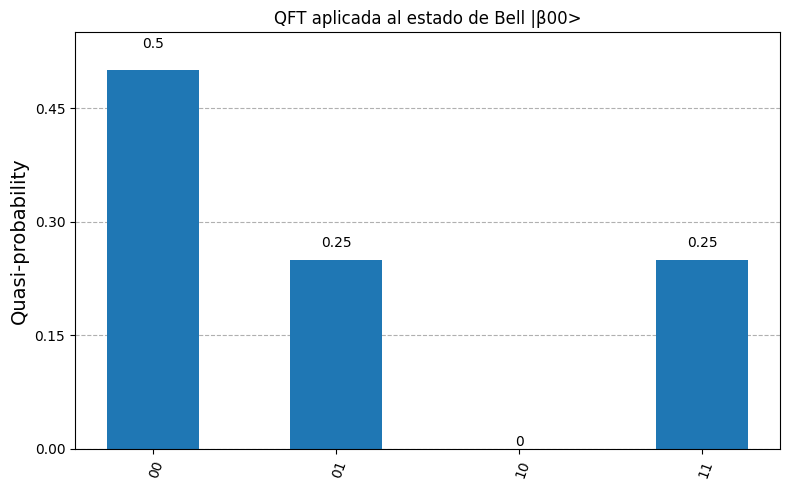

In [41]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

# Creamos un circuito de 2 qubits
qc = QuantumCircuit(2)

# Preparamos el estado de Bell |β00> = (|00> + |11>)/√2
qc.h(0)
qc.cx(0, 1)
print("Estado de Bell:      ", np.round(Statevector.from_instruction(qc).data, 4))

# Aplicamos la QFT de 2 qubits
qc.compose(miQFT(2), inplace=True)
estado_final = Statevector.from_instruction(qc)
print("Después de la QFT:   ", np.round(estado_final.data, 4))

# Comparamos con el cálculo directo F4·x
F4 = 0.5 * np.array([[1, 1, 1, 1],
                     [1, 1j, -1, -1j],
                     [1, -1, 1, -1],
                     [1, -1j, -1, 1j]])
x = np.array([1, 0, 0, 1]) / np.sqrt(2)
print("¿Coincide con F4·x?  ", np.allclose(estado_final.data, F4 @ x))

# Calculamos las probabilidades de cada estado
probabilidades = estado_final.probabilities_dict()
print("Probabilidades:      ", {str(k): round(float(v), 4) for k, v in probabilidades.items()})

# Graficamos el histograma
plot_histogram(
    probabilidades,
    title="QFT aplicada al estado de Bell |β00>",
    figsize=(8, 5)
)

Los ejemplos anteriores muestran que la QFT transforma las amplitudes y fases de los estados cuánticos, produciendo diferentes distribuciones de probabilidad.

Observamos que los histogramas permiten visualizar las probabilidades de medición, pero no muestran directamente las fases relativas. Además, comprobamos cómo la interferencia constructiva y destructiva puede modificar estas probabilidades.

---

```
  |\__/,|   (`\
  |_ _  |.--.) )
  ( T   )     /
 (((^_(((/(((_/
```

# **Mini actividad 2. Fases que el histograma no muestra**

En los ejemplos de la sección 2.4.1 vimos que la QFT de un estado de la base produce un histograma uniforme. Veamos qué información queda escondida en las fases, con $n=2$ qubits y la convención de Qiskit $\ket{q_1q_0}$.

### **Respuestas:**

1. **Predicción con las columnas de la matriz $F_4$:**
   $$F_4 = \frac{1}{2} \begin{pmatrix} 1 & 1 & 1 & 1 \\ 1 & i & -1 & -i \\ 1 & -1 & 1 & -1 \\ 1 & -i & -1 & i \end{pmatrix}$$
   - Para $\ket{00} = \ket{0}$ (columna 0): $QFT\ket{00} = \frac{1}{2}\big(\ket{00} + \ket{01} + \ket{10} + \ket{11}\big)$, con amplitudes $\left(\frac{1}{2}, \frac{1}{2}, \frac{1}{2}, \frac{1}{2}\right)$.
   - Para $\ket{10} = \ket{2}$ (columna 2, pues $q_1=1, q_0=0$): $QFT\ket{10} = \frac{1}{2}\big(\ket{00} - \ket{01} + \ket{10} - \ket{11}\big)$, con amplitudes $\left(\frac{1}{2}, -\frac{1}{2}, \frac{1}{2}, -\frac{1}{2}\right)$.
   - **¿Sus histogramas son iguales?** Sí. En ambos casos, la probabilidad de medir cada uno de los 4 estados base es $|\pm 1/2|^2 = 1/4 = 0.25$ ($25\%$ uniforme). La medición en la base computacional destruye la fase y no puede distinguir entre ambos estados.

2. **Forma factorizada como producto de estados $\ket{+}$ y $\ket{-}$:**
   - $QFT\ket{00} = \left(\frac{\ket{0} + \ket{1}}{\sqrt{2}}\right) \otimes \left(\frac{\ket{0} + \ket{1}}{\sqrt{2}}\right) = \ket{+} \otimes \ket{+} = \ket{++}$
   - $QFT\ket{10} = \left(\frac{\ket{0} + \ket{1}}{\sqrt{2}}\right) \otimes \left(\frac{\ket{0} - \ket{1}}{\sqrt{2}}\right) = \ket{+} \otimes \ket{-} = \ket{+-}$

3. **Efecto de las compuertas Hadamard finales:**
   - Dado que $H\ket{+} = \ket{0}$ y $H\ket{-} = \ket{1}$:
     - Para $QFT\ket{00}$: $(H \otimes H)\ket{++} = \ket{00}$ (se mide $\ket{00}$ con probabilidad $1.0$).
     - Para $QFT\ket{10}$: $(H \otimes H)\ket{+-} = \ket{01}$ en orden $\ket{q_1 q_0}$ con $q_1=0, q_0=1$ (se mide $\ket{01}$ con probabilidad $1.0$).
   - Las compuertas Hadamard rotan la base de medición de la base computacional $\{\ket{0}, \ket{1}\}$ a la base de Hadamard $\{\ket{+}, \ket{-}\}$, convirtiendo la información de las fases relativas en diferencias de amplitud computacional distinguibles unívocamente.


In [42]:
#    /\_____/\   ── Mini actividad 2 ── Fases ocultas en QFT ──────────────────
#   ( o   o  )   Distinción de estados mediante Hadamard
#    >  ▽  <
# ────────────────────────────────────────────────────────────────────────────
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

for etiqueta in ["00", "10"]:
    qc = QuantumCircuit(2)
    if etiqueta == "10":
        qc.x(1)                                   # prepara |10>: en Qiskit |q1 q0>, q1 vale 1
    qc.compose(miQFT(2), inplace=True)           # QFT de 2 qubits

    estado = Statevector.from_instruction(qc)
    print(f"QFT|{etiqueta}>")
    print("   amplitudes    :", np.round(estado.data, 4))
    print("   probabilidades:", np.round(estado.probabilities(), 4))

    qc.h(0)                                       # Hadamard en ambos qubits
    qc.h(1)
    print("   después de H en ambos qubits:",
          np.round(Statevector.from_instruction(qc).probabilities(), 4))


QFT|00>
   amplitudes    : [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]
   probabilidades: [0.25 0.25 0.25 0.25]
   después de H en ambos qubits: [1. 0. 0. 0.]
QFT|10>
   amplitudes    : [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j]
   probabilidades: [0.25 0.25 0.25 0.25]
   después de H en ambos qubits: [0. 1. 0. 0.]


<a id="2.5"></a>
## 2.5. QFT Inversa

La Transformada Cuántica de Fourier inversa, denotada por $QFT^{-1}$, permite invertir la transformación realizada por la QFT.

Dado que la QFT es una transformación unitaria, su inversa coincide con su adjunta:

$$
QFT^{-1}=QFT^\dagger
$$
Esta transformación desempeña un papel importante en algoritmos cuánticos como el algoritmo de Shor y la estimación cuántica de fase.

La representación matricial de la QFT inversa está dada por:

$$QFT^\dagger =  \frac{1}{\sqrt{N}} \pmatrix{1 & 1 & 1 &1  & \cdots & 1\\ 1 & \omega^{-1} & \omega^{-2} & \omega^{-3} & \cdots& \omega^{-(N-1)} \\ 1 & \omega^{-2} &\omega^{-4} & \omega^{-6}  & \cdots& \omega^{-(2N-2)} \\ 1 & \omega^{-3} & \omega^{-6} & \omega^{-9} & \cdots& \omega^{-(3N-3)} \\ \vdots &  \vdots &  \vdots &  \vdots &  \ddots &  \vdots \\ 1 & \omega^{-(N-1)} & \omega^{-(2N-2)} & \omega^{-(3N-3)} & \cdots& \omega^{-(N-1)(N-1)}}$$

Para implementarla, podemos simplemente indicar que queremos la versión inversa del circuito con el método `inverse()`, o indicar el parámetro `inverse=True` en la clase `QFT`:

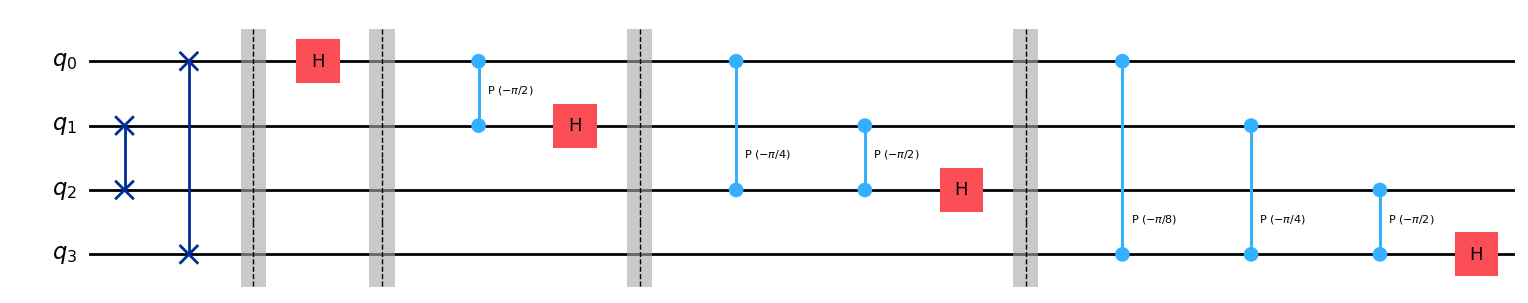

In [43]:
mi_qft_qc4.inverse().draw('mpl')

/tmp/ipykernel_1226/209078733.py:1: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft_qc4 = QFT(4, inverse=True, insert_barriers=True)


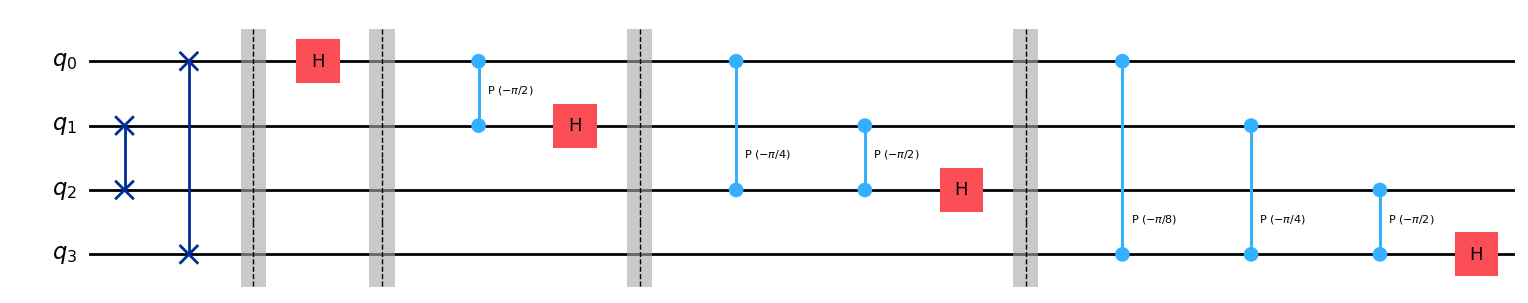

In [44]:
qft_qc4 = QFT(4, inverse=True, insert_barriers=True)
qft_qc4.decompose().draw('mpl')

### Construcción del circuito de la $QFT$ inversa

Usar `inverse()` funciona, pero no muestra **por qué** el circuito resultante tiene la forma que tiene. A continuación construimos $QFT^\dagger$ compuerta por compuerta, a partir del circuito de `miQFT(n)`.

#### 1. Principio general: invertir un circuito

Un circuito es un producto de compuertas unitarias. Si las compuertas se aplican en el orden $G_1, G_2, \ldots, G_L$, el operador total es

$$
U = G_L\,G_{L-1}\cdots G_2\,G_1 ,
$$

(la compuerta que actúa primero queda a la derecha). Como $(AB)^\dagger = B^\dagger A^\dagger$,

$$
U^{-1}=U^\dagger = G_1^\dagger\,G_2^\dagger\cdots G_{L-1}^\dagger\,G_L^\dagger .
$$

Es decir, para invertir un circuito hay que hacer dos cosas:

1. **Recorrerlo al revés**: la última compuerta de $U$ es la primera de $U^\dagger$.
2. **Reemplazar cada compuerta por su adjunta** $G^\dagger$.

Basta, entonces, con conocer la adjunta de las tres compuertas que usa la $QFT$.

#### 2. Adjunta de cada compuerta

**Hadamard.** La matriz $H=\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ es real y simétrica, así que $H^\dagger=H$. Además $H^2=I$:

$$
H^\dagger = H .
$$

La Hadamard es su propia inversa: en la $QFT^\dagger$ aparece **la misma** compuerta, solo que en otra posición.

**Fase controlada.** En la base $\ket{00},\ket{01},\ket{10},\ket{11}$, $CP(\theta)$ es diagonal, y la adjunta de una matriz diagonal conjuga cada entrada. Como $\left(e^{i\theta}\right)^*=e^{-i\theta}$:

$$
CP(\theta)^\dagger=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&1&0\\0&0&0&e^{-i\theta}\end{pmatrix}=CP(-\theta).
$$

Por eso, en la $QFT^\dagger$ las rotaciones controladas tienen **ángulos negativos**: $CP\left(\frac{\pi}{2^{m}}\right)$ se convierte en $CP\left(-\frac{\pi}{2^{m}}\right)$. Deshacer una rotación de fase significa girar el mismo ángulo en sentido contrario. Como la matriz es simétrica respecto a los dos qubits, el control y el objetivo se pueden intercambiar.

**SWAP.** Intercambiar dos veces deja todo igual, $SWAP^2=I$, y la matriz es real y simétrica:

$$
SWAP^\dagger = SWAP .
$$

Los $SWAP$ no cambian de forma, solo de lugar: pasan del **final** de la $QFT$ al **principio** de la $QFT^\dagger$. Además, los $\left\lfloor n/2\right\rfloor$ intercambios actúan sobre parejas de qubits distintas, $(q_i, q_{n-1-i})$, así que conmutan entre sí y su orden interno no importa.

| Compuerta en $QFT$ | Adjunta en $QFT^\dagger$ | Qué cambia |
|:-:|:-:|:--|
| $H$ | $H$ | Nada (es autoinversa) |
| $CP(\theta)$ | $CP(-\theta)$ | El signo del ángulo |
| $SWAP$ | $SWAP$ | Nada (es autoinversa) |

#### 3. Del circuito de la $QFT$ al de la $QFT^\dagger$

Con la convención de Qiskit $\ket{q_{n-1}\cdots q_1q_0}$, `miQFT(n)` aplica:

- Para $j=n-1, n-2, \ldots, 0$ (del qubit más significativo al menos significativo), un **bloque** $B_j$: primero $H$ sobre $q_j$ y luego $CP\left(\frac{\pi}{2^{j-k}}\right)$ con control $q_k$ y objetivo $q_j$, para $k=j-1,\ldots,0$.
- Al final, los $SWAP$ $(q_i,q_{n-1-i})$, que llamaremos $S$.

En forma de operador,

$$
QFT = S\,B_0\,B_1\cdots B_{n-1},\qquad
B_j = CP_{0\to j}\left(\tfrac{\pi}{2^{j}}\right)\cdots CP_{j-1\to j}\left(\tfrac{\pi}{2}\right)\,H_j .
$$

Aplicando la regla de la sección 1:

$$
QFT^\dagger = B_{n-1}^\dagger\cdots B_1^\dagger\,B_0^\dagger\,S,\qquad
B_j^\dagger = H_j\,CP_{j-1\to j}\left(-\tfrac{\pi}{2}\right)\cdots CP_{0\to j}\left(-\tfrac{\pi}{2^{j}}\right).
$$

Leído como circuito, de izquierda a derecha en el tiempo, queda:

1. **Primero los $SWAP$**: $(q_i,q_{n-1-i})$ para $i=0,\ldots,\left\lfloor n/2\right\rfloor-1$.
2. Para $j=0,1,\ldots,n-1$ (ahora **de menos a más significativo**):
   1. Las rotaciones $CP\left(-\frac{\pi}{2^{j-k}}\right)$ con control $q_k$ y objetivo $q_j$, para $k=0,1,\ldots,j-1$ (de la más fina a la más gruesa, al revés que en la $QFT$).
   2. **Después** la Hadamard sobre $q_j$. En la $QFT$ la $H$ iba antes de las rotaciones; en la inversa va después.

El número de compuertas es el mismo que en la $QFT$: $n$ Hadamard, $\frac{n(n-1)}{2}$ fases controladas y $\left\lfloor n/2\right\rfloor$ $SWAP$, es decir, $O(n^2)$.

#### 4. Por qué funciona: la $QFT^\dagger$ "lee" las fases

El orden anterior se obtuvo de forma mecánica, pero también tiene una interpretación directa. Sea $x=\sum_{m=0}^{n-1}x_m2^m$. Por la sección 2.3, después de la $QFT$ cada qubit está en un estado de la forma $\frac{1}{\sqrt2}\left(\ket{0}+e^{2\pi i\,\varphi}\ket{1}\right)$, y los $SWAP$ del inicio de la $QFT^\dagger$ dejan al qubit $q_j$ con la fase

$$
\varphi_j=[0.x_jx_{j-1}\cdots x_0]_2=\frac{x_j}{2}+\frac{x_{j-1}}{4}+\cdots+\frac{x_0}{2^{j+1}} .
$$

El término de $x_k$ (con $k<j$) aporta a la fase el ángulo $2\pi\cdot\frac{x_k}{2^{j-k+1}}=\frac{\pi}{2^{j-k}}\,x_k$.

- **$j=0$:** $q_0$ tiene fase $2\pi[0.x_0]=\pi x_0$, es decir, está en $\frac{1}{\sqrt2}\left(\ket{0}+(-1)^{x_0}\ket{1}\right)$. Una $H$ lo lleva a $\ket{x_0}$.
- **$j=1$:** $q_1$ tiene fase $\pi x_1+\frac{\pi}{2}x_0$. Como $q_0$ ya vale $\ket{x_0}$, la compuerta $CP\left(-\frac{\pi}{2}\right)$ controlada por $q_0$ resta $\frac{\pi}{2}$ justo cuando $x_0=1$. Queda la fase $\pi x_1$, y la $H$ da $\ket{x_1}$.
- **En general**, en el paso $j$ los qubits $q_0,\ldots,q_{j-1}$ ya contienen $\ket{x_0},\ldots,\ket{x_{j-1}}$. Cada $CP\left(-\frac{\pi}{2^{j-k}}\right)$ controlada por $q_k$ cancela la contribución de $x_k$, y solo queda $e^{i\pi x_j}=\pm1$. La $H$ convierte ese signo en el bit $\ket{x_j}$.

Esto explica las tres inversiones:

- Los **ángulos negativos** "desenrollan" las fases que la $QFT$ había acumulado.
- La **$H$ va al final de cada bloque**, porque solo puede leer el bit cuando la fase ya quedó reducida a $0$ o $\pi$.
- Los **qubits se procesan de $q_0$ hacia $q_{n-1}$**, porque cada paso usa como control los bits que ya se recuperaron. Los $SWAP$ van primero para que cada fase quede en el qubit donde se va a decodificar.

Al terminar, el registro está en $\ket{x_{n-1}\cdots x_1x_0}=\ket{x}$, es decir, $QFT^\dagger\,QFT\ket{x}=\ket{x}$. Esta es exactamente la operación que usa la estimación de fase (sección 3): ahí la fase codificada es $\phi$ en lugar de $x/N$.

#### 5. Ejemplo: $n=2$

Para dos qubits, `miQFT(2)` aplica $H(q_1)\to CP\left(\frac{\pi}{2}\right)_{q_0\to q_1}\to H(q_0)\to SWAP(q_0,q_1)$. Al invertir el orden y conjugar cada compuerta:

$$
QFT_4^\dagger:\quad SWAP(q_0,q_1)\ \longrightarrow\ H(q_0)\ \longrightarrow\ CP\left(-\tfrac{\pi}{2}\right)_{q_0\to q_1}\ \longrightarrow\ H(q_1).
$$

Su matriz es la conjugada transpuesta de $F_4$:

$$
F_4^\dagger=\frac12\begin{pmatrix}1&1&1&1\\1&-i&-1&i\\1&-1&1&-1\\1&i&-1&-i\end{pmatrix},
$$

que coincide con la forma general de la celda anterior, con $\omega^{-1}=-i$. Por ejemplo, si se aplica a $F_4\ket{01}=\frac12\left(\ket{00}+i\ket{01}-\ket{10}-i\ket{11}\right)$, se recupera $\ket{01}$.

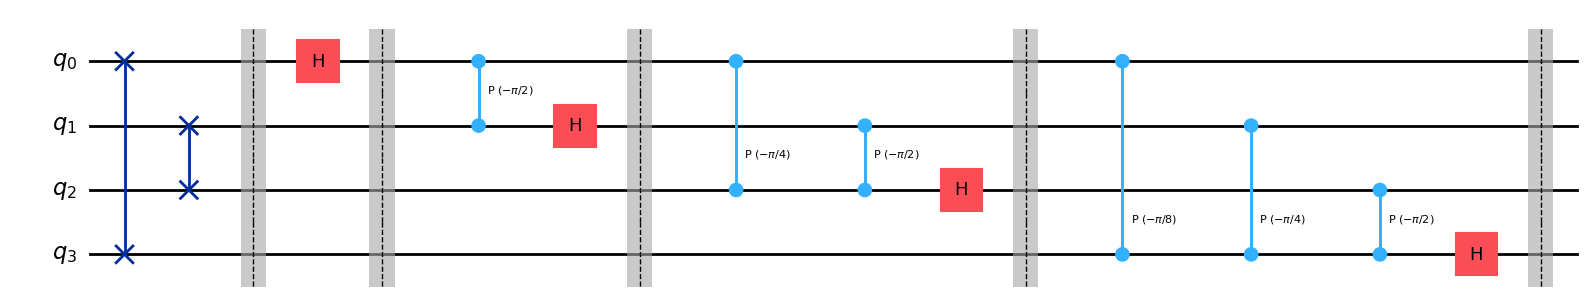

In [45]:
from qiskit import QuantumCircuit   # clase para construir circuitos cuánticos
import numpy as np                  # se usa np.pi para los ángulos de fase


def miQFTInv(n):
    """
    Construye "a mano" el circuito de la QFT inversa (QFT†) de n qubits.

    Se obtiene recorriendo al revés el circuito de miQFT(n) y reemplazando
    cada compuerta por su adjunta:  H† = H,  CP(θ)† = CP(-θ),  SWAP† = SWAP.
    No usa QFT, QFTGate, inverse() ni UnitaryGate.

    Convención de Qiskit: |q_{n-1} ... q_1 q_0>, con q_0 el bit menos significativo.

    Parámetros
    ----------
    n : int
        Número de qubits (dimensión N = 2**n).

    Regresa
    -------
    QuantumCircuit
        Circuito de n qubits que implementa F_N†.
    """
    qft_inv = QuantumCircuit(n, name="QFT†")   # circuito vacío de n qubits; el nombre aparece si se usa como bloque

    # ── Paso 1: SWAPs ────────────────────────────────────────────────────────
    # En miQFT los SWAP van al FINAL; en la inversa van al PRINCIPIO.
    # Como SWAP† = SWAP, la compuerta es la misma: solo cambia de posición.
    for i in range(n // 2):                    # ⌊n/2⌋ intercambios: (q_0, q_{n-1}), (q_1, q_{n-2}), ...
        qft_inv.swap(i, n - 1 - i)             # intercambia el qubit i con su "espejo" n-1-i
    qft_inv.barrier()                          # separador visual (no afecta el operador)

    # ── Paso 2: bloques de rotaciones + Hadamard, en orden INVERSO a miQFT ──
    # miQFT recorre j = n-1, ..., 0; la inversa recorre j = 0, 1, ..., n-1.
    for j in range(n):                         # j = qubit objetivo del bloque, de q_0 hacia q_{n-1}

        # Rotaciones controladas con ángulo NEGATIVO, porque CP(θ)† = CP(-θ).
        # miQFT recorre k = j-1, ..., 0; aquí se recorre al revés: k = 0, ..., j-1.
        for k in range(j):                     # k = qubit de control (ya decodificado como |x_k>)
            qft_inv.cp(-np.pi / 2**(j - k),    # ángulo -π/2^(j-k): cancela la fase que aportó x_k
                       k,                      # control: q_k
                       j)                      # objetivo: q_j

        # La Hadamard va DESPUÉS de las rotaciones (en miQFT iba antes), porque H† = H.
        # Convierte la fase restante e^{iπ x_j} = ±1 en el bit |x_j>.
        qft_inv.h(j)
        qft_inv.barrier()                      # separador visual entre bloques

    return qft_inv                             # objeto QuantumCircuit


# Circuito de la QFT inversa para 4 qubits (comparar con mi_qft_qc4.inverse() de arriba)
mi_qft_inv_qc4 = miQFTInv(4)
mi_qft_inv_qc4.draw('mpl')

In [46]:
from qiskit.quantum_info import Operator, Statevector
from qiskit.circuit.library import QFT


def matriz_Fourier(n):
    """Matriz analítica F_N con entradas (F_N)_{jk} = ω^{jk}/√N, ω = e^{2πi/N}."""
    N = 2**n                                       # dimensión del espacio
    idx = np.arange(N)                             # índices 0, 1, ..., N-1
    return np.exp(2j*np.pi*np.outer(idx, idx)/N) / np.sqrt(N)


for n in range(1, 7):                              # se prueba con 1 a 6 qubits
    U_inv  = Operator(miQFTInv(n)).data            # matriz unitaria de nuestro circuito
    F      = matriz_Fourier(n)                     # matriz analítica de la QFT
    F_dag  = F.conj().T                            # F† = conjugada transpuesta

    igual_analitica = np.allclose(U_inv, F_dag)                                    # ¿miQFTInv = F†?
    igual_inverse   = np.allclose(U_inv, Operator(miQFT(n).inverse()).data)        # ¿= inverse() de miQFT?
    igual_qiskit    = np.allclose(U_inv, Operator(QFT(n, inverse=True)).data)      # ¿= QFT de Qiskit?
    identidad       = np.allclose(Operator(miQFT(n)).data @ U_inv, np.eye(2**n))   # ¿QFT·QFT† = I?

    # Ida y vuelta sobre TODOS los estados base: |x> → QFT → QFT† → |x>
    ida_vuelta = True
    for x in range(2**n):
        qc = QuantumCircuit(n)
        qc.compose(miQFT(n), inplace=True)         # QFT
        qc.compose(miQFTInv(n), inplace=True)      # QFT†
        final = Statevector.from_label(format(x, f'0{n}b')).evolve(qc)
        ida_vuelta &= np.isclose(abs(final.data[x])**2, 1.0)   # toda la probabilidad regresa a |x>

    print(f"n={n}:  =F† {igual_analitica} | =inverse() {igual_inverse} | "
          f"=QFT(inverse=True) {igual_qiskit} | QFT·QFT†=I {identidad} | ida y vuelta {ida_vuelta}")

/tmp/ipykernel_1226/1881170936.py:19: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  igual_qiskit    = np.allclose(U_inv, Operator(QFT(n, inverse=True)).data)      # ¿= QFT de Qiskit?


n=1:  =F† True | =inverse() True | =QFT(inverse=True) True | QFT·QFT†=I True | ida y vuelta True
n=2:  =F† True | =inverse() True | =QFT(inverse=True) True | QFT·QFT†=I True | ida y vuelta True
n=3:  =F† True | =inverse() True | =QFT(inverse=True) True | QFT·QFT†=I True | ida y vuelta True
n=4:  =F† True | =inverse() True | =QFT(inverse=True) True | QFT·QFT†=I True | ida y vuelta True
n=5:  =F† True | =inverse() True | =QFT(inverse=True) True | QFT·QFT†=I True | ida y vuelta True
n=6:  =F† True | =inverse() True | =QFT(inverse=True) True | QFT·QFT†=I True | ida y vuelta True


### Discusión sobre la cantidad de compuertas

Para el primer qubit, aplicamos una sola compuerta de Hadamard seguida de $n-1$ compuertas de rotación controlada, lo que suma un total de $n$ compuertas.

Para el segundo qubit, aplicamos una sola compuerta de Hadamard seguida de $n-2$ compuertas de rotación controlada, lo que suma un total de $n-1$ compuertas.

Entonces, en total se requieren $n + (n-1) + \cdots + 1 = \dfrac{n(n+1)}{2}$ compuertas.

Además, se requieren $\left\lfloor \frac{n}{2}\right\rfloor$ compuertas SWAP para invertir el orden de los qubits, cada una de las cuales puede implementarse utilizando tres compuertas CNOT.

En resumen, se requieren del orden $O(n^2)$ compuertas para aplicar $QFT$ a un sistema de $n$ qubits representado por un vector de tamaño $N=2^n$.

La Transformada Rápida de Fourier (FFT) es un algoritmo clásico que permite calcular la Transformada Discreta de Fourier (DFT) de $N=2^n$ entradas utilizando $O(N\log N)$ operaciones, equivalentes a $O(n2^n)$. En comparación, la QFT puede implementarse mediante un circuito de $O(n^2)$ compuertas, e incluso existen implementaciones aproximadas que requieren $O(n\log n)$ compuertas.

Sin embargo, esta diferencia de complejidad no implica que la QFT pueda sustituir directamente a la FFT clásica. Esto se debe a que las amplitudes del estado cuántico resultante no pueden obtenerse directamente mediante una medición y a que la preparación eficiente del estado de entrada no siempre está garantizada.

<a id="3"></a>
# 3. Estimación Cuántica de Fase (QPE)

En esta sección hablaremos de una aplicación de la Transformada Cuántica de Fourier, que nos llevará en el camino hacia el Algoritmo de Shor.

Para una matriz dada $ A $, un vector $ \vec{v} $ distinto de cero se denomina su vector propio (eigenvector) si existe un valor escalar $ \lambda $ llamado valor propio (eigenvalor) que satisface

$$ A \cdot \vec{v} = \lambda \cdot \vec{v} $$

Las matrices unitarias preservan la longitud. Por lo tanto, sus valores propios deben tener una longitud de $1$, por lo que tienen la forma

$$ \lambda={\large e}^{\large 2 \pi i \phi} $$

para algún $\phi \in [0,1)$.

Nuestro objetivo es, para una matriz unitaria dada $ U $ y su vector propio $ \ket{u} $, estimar la fase $ \phi $ del valor propio correspondiente, es decir $ {\large e}^{\large 2 \pi i \phi} $.

La matriz $ U^k $ es la $ k $-ésima potencia de $ U $.

Dado que tenemos la relación

$$ U \ket{u} = {\large e}^{\large 2 \pi i \phi} \ket{u} $$

entonces podemos observar que

$$ U^{\large k} \ket{u} = \left( {\large e}^{\large 2 \pi i \phi} \right)^{\large k} \ket{u} = {\large e}^{\large 2 \pi i \phi k} \ket{u} $$

<div class="alert alert-block alert-info">
    <strong>Ejemplo</strong>: Mostrar que $\ket{-}$ y $\ket{+}$ son eigenvectores del operador $X$ con eigenvalores $-1$ y $1$ respectivamente

\begin{align*}
X \ket{-} = X \frac {\ket{0} - \ket{1}} {\sqrt{2}}
& =  \frac {\ket{1} - \ket{0}} {\sqrt{2}}\\
& = -\frac {\ket{0} - \ket{1}} {\sqrt{2}}\\
& = -\ket{-}
\end{align*}


\begin{align*}
X \ket{+} = X \frac {\ket{0} + \ket{1}} {\sqrt{2}}
& =  \frac {\ket{1} + \ket{0}} {\sqrt{2}}\\
& = \frac {\ket{0} + \ket{1}} {\sqrt{2}}\\
& = \ket{+}
\end{align*}

Por lo tanto, $ \ket{-}$ y $\ket{+}$ son vectores propios (o estados propios) del operador $ X $ con los valores propios $-1$ y $1$ respectivamente.

### Operador U-controlado

Sea $ U $ un operador unitario con estado propio $ \ket{\psi} $ y valor propio $ {\large e}^{\large 2\pi i \phi} $ tal que $ U\ket{\psi} = {\large e}^{\large 2{\pi}i{\phi}} \ket{\psi}$.

Comprobamos el efecto del operador $ U $ controlado ($CU$) sobre el qubit de control.

A continuación se muestran los casos en los que el qubit de control está en el estado $ \ket{0} $ ó $ \ket{1} $.

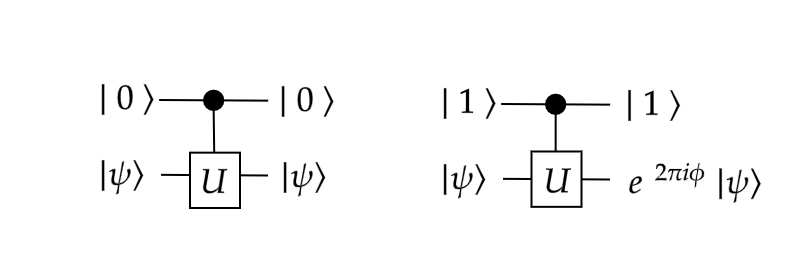

En el primer caso, el operador $ U $ no se aplica ya que el qubit de control está en $ \ket{0} $. Por lo tanto, tenemos:

$$ CU(\ket{0}\ket{\psi}) \rightarrow \ket{0}\ket{\psi} $$

En el segundo caso, el operador $ U $ se aplica al estado $ \ket{\psi} $ ya que el qubit de control está en $ \ket{1} $. Por lo tanto, tenemos:

$$ CU(\ket{1}\ket{\psi}) \rightarrow {\large e}^{\large 2{\pi}i{\phi}}\ket{1}\ket{\psi} $$

El operador $ CU $ coloca una fase de $ {\large e}^{\large 2\pi i \phi} $ delante del estado $ \ket{1} $ cuando el qubit de control está en superposición de los estados $ \ket{0} $ y $ \ket{1} $; es decir,

$$ \begin{array}{rcl}
CU \left( \left( \dfrac{ \ket{0} + \ket{1} }{ \sqrt{2} } \right)  \ket{\psi} \right) & = &  \dfrac{1}{\sqrt{2}} \Bigg( CU \Big( \ket{0}\ket{\psi} + \ket{1}\ket{\psi} \Big) \Bigg) \\
& = & \dfrac{1}{\sqrt{2}} \Big( CU\ket{0}\ket{\psi} + CU \ket{1}\ket{\psi} \Big) \\
& = & \dfrac{1}{\sqrt{2}} \Big( \ket{0} \ket{\psi} + {\large e}^{\large 2{\pi}i{\phi}}\ket{1}\ket{\psi} \Big) \\
& = & \dfrac{1}{\sqrt{2}} \Big( \big( \ket{0} + {\large e}^{\large 2{\pi}i{\phi}}\ket{1} \big) \ket{\psi} \Big) \\
& = & \Bigg( \dfrac{ \ket{0} + {\large e}^{\large 2{\pi}i{\phi}} \ket{1} }{\sqrt{2}} \Bigg) \ket{\psi}
\end{array}$$

Por lo tanto, para un estado arbitrario, tenemos que

$$\alpha \ket{0}\ket{\psi} + \beta \ket{1}\ket{\psi} \xrightarrow{CU} \alpha \ket{0}\ket{ \psi} ~+~ {\large e}^{\large 2{\pi}i{\phi}} \beta \ket{1}\ket{\psi} = \left(\alpha \ket{0} ~+~ {\large e}^{\large 2{ \pi}i{\phi}} \beta \ket{1}\right)\ket{\psi}$$

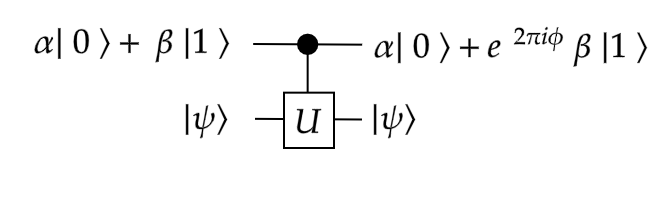

### Estimación de valores propios del operador $X$

Recordemos que $ \ket{+} $ y $ \ket{-} $ son los estados propios del operador $X$. Si aplicamos el operador $ CX $ al siguiente estado cuántico donde $ \ket{\psi} $ es $ \ket{+} $ o $ \ket{-} $, entonces, tenemos que:

\begin{align*}
CX \left(\frac {\ket{0} + \ket{1}} {\sqrt{2}} \ket{\psi} \right) \rightarrow \frac {\ket{0} + (-1)^x \ket{1}} {\sqrt{2}}\ket{\psi}
\end{align*}

Para determinar el valor de $x$, aplicamos una compuerta Hadamard al qubit de control y posteriormente realizamos una medición en la base computacional.

Si el resultado es $ \ket{0} $, entonces $ x = 0 $ y si el resultado es $ \ket{1} $, entonces $ x = 1 $.

Notemos que este es un caso especial del problema de estimación de fase en el que intentamos estimar los valores propios del operador $ X $. En este caso, $ \phi $ es $ 0 $ o $ \frac{1}{2} $, que se puede determinar mediante un operador Hadamard. A continuación, veremos cómo lograr esto en general.

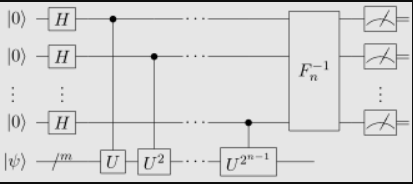

<a id="3.1"></a>
## 3.1. Algoritmo de QPE

Nuestra matriz unitaria $ U $ y el estado $\ket{\psi} $ es el vector propio dado.

Usamos dos registros.

- El primer registro contiene $ t $ qubits que están en el estado $ \ket{0} $.
  - $ t $ depende de la cantidad de dígitos de precisión y la probabilidad de éxito al estimar $ \phi $. Más adelante veremos los detalles de $ t $.
  - Nombramos estos qubits como $ q_1,q_2,\ldots,q_t$.
    
- El segundo registro almacena $ \ket{\psi} $.

Aplicamos una serie de operadores controlados $ U^{2^{\huge j}} $ para $ j \in \{0,\ldots,t-1 \} $.

### Estado inicial

Comenzamos en el estado
$$\underbrace{\left(\ket{0}\otimes\cdots\otimes\ket{0}\right)}_{1er~registro}\underbrace{\ket{\psi}}_{2do~registro}$$

### Operadores Hadamard

Primero aplicamos una compuerta Hadamard a cada qubit en el primer registro.

Entonces, el nuevo estado cuántico es

$$ \underbrace{\dfrac {1}{2^{t/2}} \big( \left(\ket{0}+\ket{1}\right) \otimes \cdots \otimes \left(\ket{0}+\ket{1}\right) \big) }_{1er~registro} \; \underbrace{ \ket{\psi} }_{2do~registro} $$

### Operadores $U^{2^{\huge j}}$ controlados

Aplicamos el operador $ U^{2^{\huge j}} $ al segundo registro, controlado por $ q_{t-j} $ en el primer registro, donde $j \in \{ 0,\ldots, t-1 \}$.

Como se explicó anteriormente, después de aplicar cada $ CU^{2^{\huge j}} $, la fase relativa del qubit de control se actualizará en consecuencia.

- **$j=0$:** Aplicamos $CU^{2^{\huge 0}}$ al segundo registro, donde $q_t$ es el qubit de control. Entonces, el estado es

$$ \underbrace{\dfrac {1}{2^{t/2}} \Big( \left(\ket{0}+\ket{1}\right) \otimes \cdots \otimes \left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^0}}\ket{1}\right) \Big) }_{1er~registro} \; \underbrace{ \ket{\psi} }_{2do~registro} $$

- **$j=1$:** Aplica $CU^{2^{\huge 1}}$ al segundo registro, donde $ q_{t-1} $ es el qubit de control. Entonces, el estado es

$$ \underbrace{\dfrac {1}{2^{t/2}} \Big( \left(\ket{0}+\ket{1}\right) \otimes \cdots \otimes \left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^1}}\ket{1}\right) \otimes \left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^0}}\ket{1}\right) \Big) }_{1er~registro} \; \underbrace{ \ket{\psi} }_{2do~registro} $$

$ ~~~~ \vdots $

- **$j=t-1$:** Aplica $CU^{2^{\huge t-1}}$ al segundo registro, donde $q_1$ es el qubit de control. Entonces, el estado es

$$ \underbrace{\dfrac {1}{2^{t/2}} \Big( \left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^{t-1}}}\ket{1}\right) \otimes \cdots \otimes \left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^1}}\ket{1}\right) \otimes \left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^0}}\ket{1}\right) \Big) }_{1er~registro} \; \underbrace{ \ket{\psi} }_{2do~registro} $$

### QFT inversa

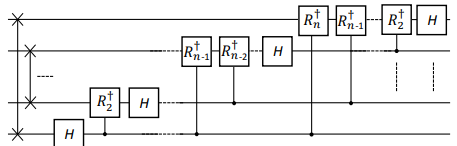


Hemos terminado con el segundo registro y podemos descartarlo.

El estado del primer registro es

$$\ket{u} = \dfrac {1}{2^{t/2}} \underbrace{\left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^{ t-1}}}\ket{1}\right)}_{q_1} \otimes \cdots \otimes \underbrace{\left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^1}}\ket{1}\right)}_{q_{t-1}} \otimes \underbrace{\left(\ket{0}+\mathbf{{\large e}^{\large 2{\pi}i\phi 2^0}}\ket{1}\right)}_{q_t}$$

De hecho, este estado es el mismo que el estado obtenido por $ QFT\ket{j} $:

$$ QFT\ket{j} = \dfrac{1}{\sqrt{N}}
 \underbrace{ \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_n ]} } \ket{1} \right) }_{q_1} \otimes
 \underbrace{ \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_{n-1}j_n ]} } \ket{1} \right) }_{q_{2} } \otimes
 \cdots \otimes
 \underbrace{ \left(\ket{0}+{\large e}^{\large 2\pi i \mathbf{[ 0.j_1\cdots j_n]}} \ket{1} \right) }_{q_n}
$$

donde $ N = 2^n $ y $ \ket{j} \in \{ \ket{0},\ldots,\ket{N-1} \} $.

La única diferencia es que $ j $ es un entero y, por lo tanto, el componente de fracción binaria de una fase relativa se almacena en $ n $ bits. Por otro lado, $ \phi $ puede utilizar una cantidad arbitraria de bits o tener una cantidad infinita de dígitos.

Para demostrar que $ \ket{u} $ y $ QFT\ket{j} $ son (casi) lo mismo, reformateamos las fases relativas en $ \ket{u} $.

Tanto $ t $ como $ n $ son el número de qubits. Podemos usarlos indistintamente.

El valor $ \phi \in [0,1) $ se representa en binario como $ [ 0.\phi_1 \phi_2 \cdots \phi_n \phi_{n+1} \cdots ] $.

Al multiplicar $\phi$ por las potencias de $2$, se desplaza el punto decimal hacia la derecha:
- $ \phi 2^0 = [ 0 \mathbf{.}\phi_1 \phi_2 \cdots \phi_n \phi_{n+1} \cdots ] $
- $ \phi 2^1 = [\phi_1 \mathbf{.} \phi_2 \cdots \phi_n \phi_{n+1} \cdots ] $
<br> $ ~~~ \vdots $
- $ \phi 2^{n-1} = [ \phi_1 \phi_2 \cdots \phi_{n-1} \mathbf{.} \phi_n \phi_{n+1} \cdots ] $

Estos valores están en el exponente de $ {\large e} $ y en la multiplicación por $ 2\pi i$. Por lo tanto, podemos eliminar las partes enteras.

$$ \ket{u} = \dfrac {1}{\sqrt{N}} \underbrace{\left(\ket{0}+{\large e}^{\large 2{\pi}i  \mathbf{[0.\phi_n\cdots]} }\ket{1} \right) }_{q_1} \otimes \underbrace{\left(\ket{0}+{\large e}^{\large 2{\pi}i \mathbf{[0.\phi_{n-1}\phi_n\cdots]} }\ket{1}\right) }_{q_2} \otimes \cdots \otimes \underbrace{\left(\ket{0}+{\large e}^{\large 2{\pi}i \mathbf{[0.\phi_1 \cdots \phi_n\cdots]} }\ket{1} \right)
}_{q_{n-1}} $$

<div class="alert alert-block alert-success">
<strong>Recordatorio</strong>: La exponencial elevada a $2\pi i$

Tenemos que

$${\large e}^{\large 2\pi i} = 1$$

Sucede lo mismo para los múltiplos de $2\pi i$, es decir,

$${\large e}^{\large m2\pi i} = 1^{\large m}=1$$


Está claro que
$$ QFT^\dagger QFT \ket{j} = \ket{j} $$

Por lo tanto, para estimar $ \phi $, podemos simplemente aplicar $ QFT^\dagger $ a $ \ket{u} $ y luego medir todos los qubits (en el primer registro).

### Circuito

A continuación se muestra el circuito completo del algoritmo de estimación de fase cuántica.

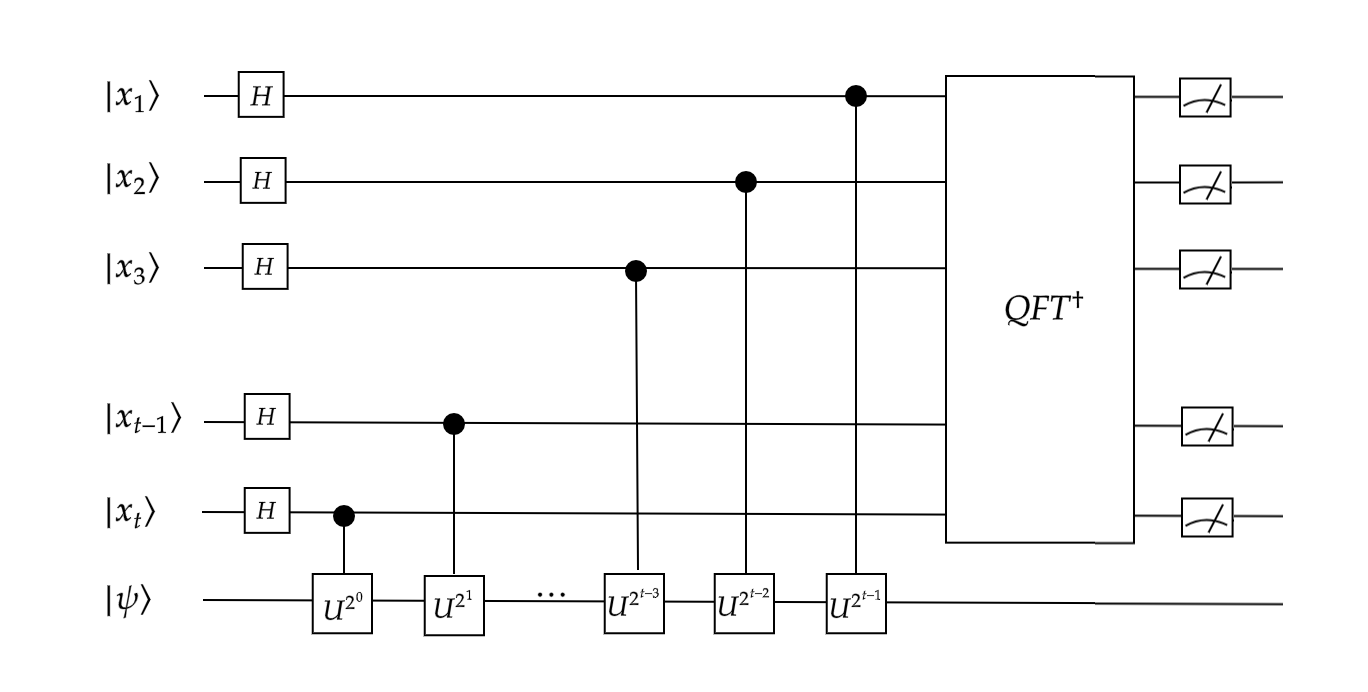

El circuito utiliza $ O(t^2) $ compuertas (operaciones) con $ t $ llamadas de $ CU^{2^{\huge j}} $.

### Salidas

Si hay $ \ket{j} \in \{ \ket{0},\ldots,\ket{N-1} \} $ que satisface que $ j = N \cdot \phi $, entonces el resultado es $ \ket{j} $ con probabilidad $1$ y por lo tanto

$$ \phi = \dfrac{j}{N} $$

De lo contrario, $ N \cdot \phi $ está entre los números enteros $ j $ y $ j+1 $ ($ 0 \leq j < j+1 \leq N-1 $), entonces el resultado será $ \ket{j} $ o $ \ket{j+1} $ con alta probabilidad. En cualquier caso, tendremos una estimación de $\phi$:

$$ \dfrac{j}{N} < \phi < \dfrac{j+1}{N} $$

Para tener una mejor estimación, se pueden usar más qubits en el primer registro, es decir, eligiendo

$$ t = m + \left \lceil \log \left (2 + \frac{1}{2\varepsilon} \right) \right \rceil $$

donde $\log$ es el logarítmo base $2$, entonces podemos aproximar $\phi$ con una precisión de $ m $ bits con una probabilidad de éxito de al menos $1 - \varepsilon$.

Si tomamos cualquier estado arbitrario en lugar de $\ket{\psi}$, obtenemos una aproximación a uno de los valores propios con cierta probabilidad. La razón es que podemos expresar cualquier estado cuántico como una combinación lineal de los vectores propios.

Como sabemos cómo implementar $QFT^{\dagger}$ de manera eficiente, también hemos obtenido un algoritmo eficiente para la estimación de fase. Muchos problemas interesantes se reducen al problema de estimación de fase.

<a id="3.2"></a>
## 3.2. Implementación en Qiskit

### Operador unitario para un solo qubit control

Consideremos un operador unitario de un solo qubit $ U $ que tiene un vector propio $ \ket{1} $ y un valor propio $ {\large e}^{\large 2\pi i \phi} $ donde $\phi = \dfrac{5}{16} $.

La compuerta `CPhaseGate(2*pi*5/16)` de Qiskit permite implementar el operador controlado $CU$, cuya fase corresponde a $\phi=\frac{5}{16}$.

In [47]:
from qiskit import QuantumCircuit
import numpy as np

def CU(circuit, power, qcontrol, target):

    circuit.cp((2*np.pi * 5/16) * (2**power), qcontrol, target)

Ahora elijamos $t=4$ e implementemos el circuito de estimación de fase para estimar $\phi$.

Utilicemos el método `QFT` de Qiskit, para el uso de la $ QFT^\dagger $.

Tengamos en cuenta que se debería obtener un resultado exacto ya que $t=4$ es lo suficientemente preciso para este caso.

/tmp/ipykernel_1226/725446676.py:21: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)


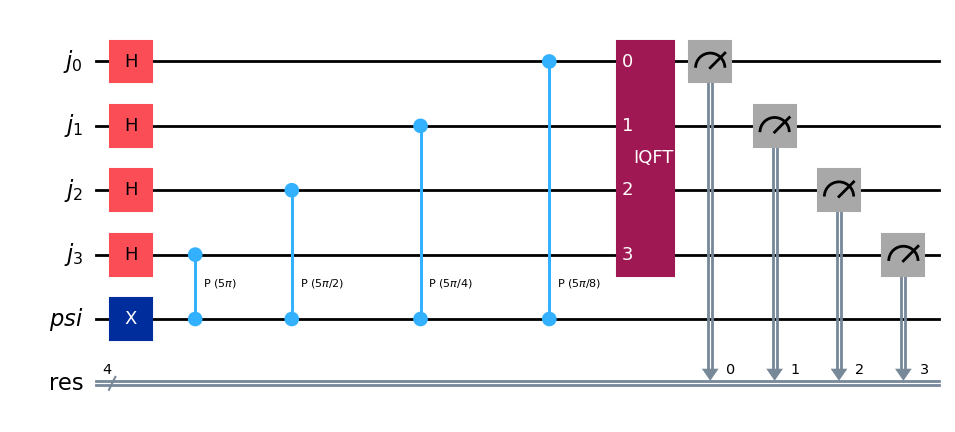

In [48]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

t = 4                                     # número de qubits en el registro de control
n = 1                                     # número de qubits en el registro que almacena el eigenvector

control = QuantumRegister(t, 'j')         # crear t qubits de control

target = QuantumRegister(n, 'psi')        # crear n qubits objetivo

circuit = QuantumCircuit(control, target) # crear el circuito

circuit.h(control)                        # aplicar Hadamard a los qubits del primer registro (control)

circuit.x(target)                         # colocar el segundo registro (target) en el estado |1>

                                          # aplicar los operadores CU^(2^j)
for j in reversed(range(t)):
    CU(circuit, j, control[j], target)    # nota que el orden es inverso porque se trata de Qiskit

                                          # agregar la QFT inversa
circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)


cr = ClassicalRegister(t, 'res')          # agregar mediciones (al registro 't' o 'control')
circuit.add_register(cr)
circuit.measure(control, cr)


display(circuit.draw('mpl'))              # mostrar el circuito

In [49]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()

job_sampler = sampler.run([circuit])

job_sampler.result()

print(job_sampler.result()[0].data.res.get_counts())

{'0101': 1024}


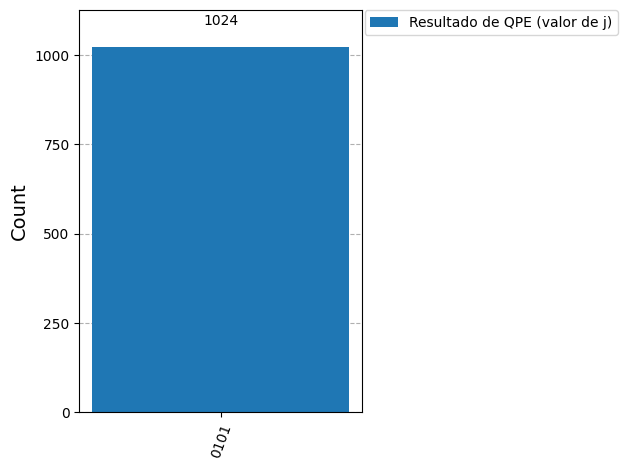

In [50]:
from qiskit.visualization import plot_histogram

plot_histogram([job_sampler.result()[0].data.res.get_counts()], legend=["Resultado de QPE (valor de j)"])

Observamos la salida $0101_2 = 5_{10}$, entonces la fase es:

$$\phi=\frac{j}{N}=\frac{5}{2^4}=\frac{5}{16}$$

¿Qué pasa si usamos solamente $t=3$?

/tmp/ipykernel_1226/2493681623.py:21: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)


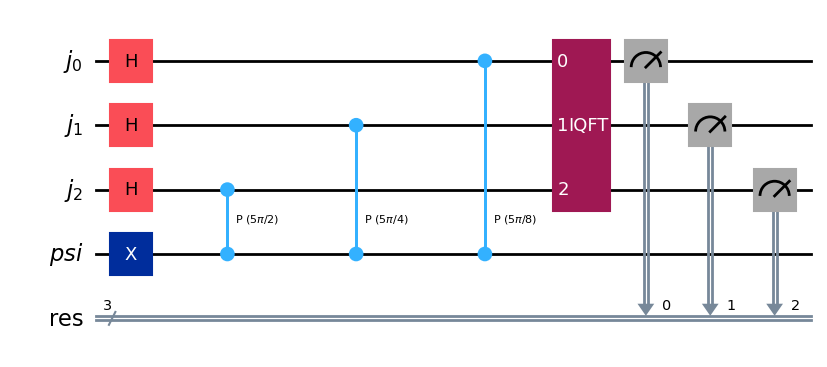

{'011': 399, '010': 440, '110': 19, '100': 54, '101': 23, '000': 20, '001': 46, '111': 23}


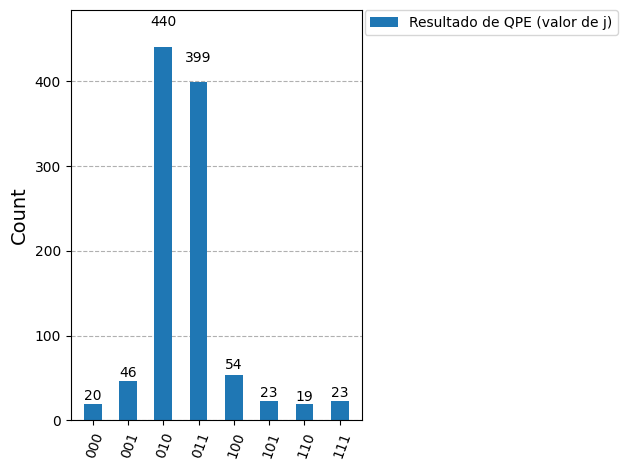

In [51]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

t = 3          # <-- cambio               # número de qubits en el registro de control
n = 1                                     # número de qubits en el registro que almacena el eigenvector

control = QuantumRegister(t, 'j')         # crear t qubits de control

target = QuantumRegister(n, 'psi')        # crear n qubits objetivo

circuit = QuantumCircuit(control, target) # crear el circuito

circuit.h(control)                        # aplicar Hadamard a los qubits del primer registro (control)

circuit.x(target)                         # colocar el segundo registro (target) en el estado |1>

                                          # aplicar los operadores CU^(2^j)
for j in reversed(range(t)):
    CU(circuit, j, control[j], target)    # nota que se itera en orden inverso porque se trata de Qiskit

                                          # agregar la QFT inversa
circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)


cr = ClassicalRegister(t, 'res')          # agregar mediciones (al registro 't' o 'control')
circuit.add_register(cr)
circuit.measure(control, cr)


display(circuit.draw('mpl'))              # mostrar el circuito



sampler = StatevectorSampler()

job_sampler = sampler.run([circuit])

job_sampler.result()

print(job_sampler.result()[0].data.res.get_counts())

plot_histogram([job_sampler.result()[0].data.res.get_counts()], legend=["Resultado de QPE (valor de j)"])

Las salidas más frecuentes son `010` y `011`, que son $2$ y $3$ en decimal respectivamente, entonces tenemos que

$$ \dfrac{2}{8} <  \phi < \dfrac{3}{8} \; \Rightarrow \; \dfrac{4}{16} <  \phi < \dfrac{6}{16}  $$

Ahora trabajemos con $\phi=0.685$.

Es necesario actualizar $CU$:

In [52]:
def CU(circuit, power, qcontrol, target):

    circuit.cp((2*np.pi * 0.685) * (2**power), qcontrol, target)

¿Cuál valor de $t$ es el que funcionará en este caso?

In [53]:
for t in range(1, 14):

    n = 1                                       # número de qubits en el registro que almacena el eigenvector

    control = QuantumRegister(t, 'j')           # crear t qubits de control

    target = QuantumRegister(n, 'psi')          # crear n qubits objetivo

    circuit = QuantumCircuit(control, target)   # crear el circuito

    circuit.h(control)                          # aplicar Hadamard a los qubits del primer registro (control)

    circuit.x(target)                           # colocar el segundo resistro (target) en el estado |1>

                                                # aplicar los operadores CU^(2^j)
    for j in reversed(range(t)):
        CU(circuit, j, control[j], target)      # nota que se itera en orden inverso porque se trata de Qiskit

                                                # agregar la QFT inversa
    circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)

    cr = ClassicalRegister(t, 'res')            # agregar mediciones
    circuit.add_register(cr)
    circuit.measure(control, cr)

    sampler = StatevectorSampler()

    job_sampler = sampler.run([circuit])

    job_sampler.result()

    data = job_sampler.result()[0].data.res.get_counts()

    max_key = max(data, key=data.get)          # encontrar la llave (número medido) con el valor máximo
    max_value = data[max_key]

    freq = int(max_key, 2)

    print(t, ":\t phi =", freq/2**t)

/tmp/ipykernel_1226/2573665120.py:20: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)


1 :	 phi = 0.5
2 :	 phi = 0.75
3 :	 phi = 0.625
4 :	 phi = 0.6875
5 :	 phi = 0.6875
6 :	 phi = 0.6875
7 :	 phi = 0.6875
8 :	 phi = 0.68359375
9 :	 phi = 0.685546875
10 :	 phi = 0.6845703125
11 :	 phi = 0.68505859375
12 :	 phi = 0.68505859375
13 :	 phi = 0.68505859375


### Operador unitario para dos qubits control

Al utilizar `MCPhaseGate` que es una compuerta multicontrolada, podemos obtener un operador para dos qubits control.

Fijamos $ \phi = 0.31415926535 $. Por lo tanto, $ \ket{11} $ es un vector propio con valor propio $e^{2\pi i\phi}$.

In [54]:
def CU2(circuit, power, control, target):

    circuit.mcp((2*np.pi * 0.31415926535) * (2**power), control, target)

In [55]:
for t in range(1, 17):

    n = 2                                       # número de qubits en el registro que almacena el eigenvector

    control = QuantumRegister(t, 'j')           # crear t qubits de control

    target = QuantumRegister(n, 'psi')          # crear n qubits objetivo

    circuit = QuantumCircuit(control, target)   # crear el circuito

    circuit.h(control)                          # aplicar Hadamard a los qubits del primer registro (control)

    circuit.x(target)                           # colocar el segundo resistro (target) en el estado |1>

                                                # aplicar los operadores CU^(2^j)
    for j in reversed(range(t)):
        CU2(circuit, j, target, control[j])     # nota que se itera en orden inverso porque se trata de Qiskit
                                                # 'mcp' espera múltiples controles, por eso se intercambia el parámetro
                                                # 'target' (que tiene dos qubits) con el parámetro 'control[j]' (que solo es un qubit)

                                                # agregar la QFT inversa
    circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)

    cr = ClassicalRegister(t, 'res')            # agregar mediciones
    circuit.add_register(cr)
    circuit.measure(control, cr)

    sampler = StatevectorSampler()

    job_sampler = sampler.run([circuit])

    job_sampler.result()

    data = job_sampler.result()[0].data.res.get_counts()

    max_key = max(data, key=data.get)          # encontrar la llave (número medido) con el valor máximo
    max_value = data[max_key]

    freq = int(max_key, 2)                     # convertir la llave de binario a decimal

    print(t, ":\t phi =", freq/2**t)

/tmp/ipykernel_1226/1293996946.py:22: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  circuit.compose(QFT(t, inverse=True), inplace=True, qubits=control)


1 :	 phi = 0.5
2 :	 phi = 0.25
3 :	 phi = 0.375
4 :	 phi = 0.3125
5 :	 phi = 0.3125
6 :	 phi = 0.3125
7 :	 phi = 0.3125
8 :	 phi = 0.3125
9 :	 phi = 0.314453125
10 :	 phi = 0.314453125
11 :	 phi = 0.31396484375
12 :	 phi = 0.314208984375
13 :	 phi = 0.314208984375
14 :	 phi = 0.31414794921875
15 :	 phi = 0.31414794921875
16 :	 phi = 0.3141632080078125


---

```
  ∧,,,∧
 (  ̳• · • ̳)
 /    づ♡
```

# **Mini actividad 3. Estimación de una fase con QPE**

Consideremos un operador $U$ de un qubit con estado propio $\ket{1}$, tal que $U\ket{1}=e^{2\pi i\phi}\ket{1}$ con $\phi=\frac{3}{8}$.

### **Respuestas:**

1. **Expansión binaria de $\phi$ y predicción con $t=3$:**
   - $\phi = \frac{3}{8} = 0.375 = \frac{0}{2} + \frac{1}{4} + \frac{1}{8} = 0.011_2$.
   - Con $t=3$ cúbits de control, el valor $2^t \phi = 2^3 \times \frac{3}{8} = 3 = 011_2$ es un **entero exacto**.
   - Por tanto, el algoritmo de QPE medirá el estado $\ket{011}$ con **probabilidad exactamente 1.0** ($100\%$ de los disparos).

2. **Código completado:** (Ver celda de código abajo con `qc.cp` y `miQFTInv`).

3. **Repetición con $t=2$ cúbits de control:**
   - Con $t=2$, $2^2 \phi = 4 \times \frac{3}{8} = 1.5$. No es un entero, por lo que la fase no puede representarse con solo 2 bits fraccionarios.
   - En consecuencia, el estado cuántico tras la $QFT^\dagger$ se divide simétricamente entre los dos enteros más próximos:
     - $j=1$ ($01_2 \implies \tilde{\phi} = 1/4 = 0.25$) con $\approx 41.5\%$ de probabilidad.
     - $j=2$ ($10_2 \implies \tilde{\phi} = 2/4 = 0.50$) con $\approx 41.5\%$ de probabilidad.
   - La estimación queda acotada en el intervalo $[0.25, 0.50]$.


In [56]:
#    ∧ ∧   ── Mini actividad 3 ── QPE para phi = 3/8 ────────────────────────
#  (=^ω^=)  Estimación exacta (t=3) vs aproximada con fuga espectral (t=2)
# ────────────────────────────────────────────────────────────────────────────
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.primitives import StatevectorSampler
import numpy as np

phi = 3/8

def qpe_mini(t, shots=1000):
    control = QuantumRegister(t, 'j')
    target = QuantumRegister(1, 'psi')
    res = ClassicalRegister(t, 'res')
    qc = QuantumCircuit(control, target, res)

    qc.h(control)                                     # superposición en los controles
    qc.x(target)                                      # estado propio |1>

    for j in range(t):
        qc.cp(2 * np.pi * phi * (2**j), control[j], target[0])  # CU^(2^j): ángulo 2π·phi·2^j

    qc.compose(miQFTInv(t), qubits=control, inplace=True)      # QFT inversa con tu función
    qc.measure(control, res)

    return StatevectorSampler().run([qc], shots=shots).result()[0].data.res.get_counts()

for t in (3, 2):
    conteos = qpe_mini(t)
    print(f"t = {t}:", conteos)
    for resultado, veces in sorted(conteos.items(), key=lambda par: -par[1])[:2]:
        print(f"   {resultado} -> phi ≈ {int(resultado, 2) / 2**t}  ({veces} veces)")


t = 3: {'011': 1000}
   011 -> phi ≈ 0.375  (1000 veces)
t = 2: {'01': 428, '10': 417, '11': 76, '00': 79}
   01 -> phi ≈ 0.25  (428 veces)
   10 -> phi ≈ 0.5  (417 veces)


<a id="4"></a>
# 4. Práctica 6

## **Instrucciones**

**A)** La tarea deberá entregarse en un **Jupyter Notebook (.ipynb) nuevo**. No se permite utilizar este mismo notebook. El notebook deberá incluir tu **nombre completo** y los ejercicios deberán estar **claramente separados y organizados**. El nombre del archivo deberá contener tu **nombre y apellidos**, o tu nombre acompañado de las **iniciales de tus apellidos**. Solo se aceptarán archivos `.ipynb`. Cualquier entrega en otro formato **no será calificada**. El archivo deberá subirse a **Google Classroom**.

**B)** La tarea es **estrictamente individual**. En caso de identificar trabajos realizados en conjunto o con contenido sustancialmente compartido, la tarea será anulada para las personas involucradas.

**C)** El uso de herramientas de **inteligencia artificial** estará fuertemente penalizado y se considerará en la calificación de cada inciso de acuerdo con el grado de uso. En caso de utilizar alguna, incluso de manera mínima, deberá indicarse explícitamente qué herramienta fue empleada, anexar los **prompts utilizados**, señalar los incisos en los que se utilizó y explicar brevemente la razón de su uso en cada caso. Cualquier uso de inteligencia artificial deberá ser **mostrado y justificado**. El uso de IA sin notificación llevará a la **anulación de la tarea**.

**D)** Los ejercicios marcados como **opcionales** otorgarán puntos extra sobre el **total de tareas**. No realizarlos **no restará puntos** de la calificación obtenida. Los puntos extra han sido **registrados y guardados**, por lo que no se verán reflejados directamente en la calificación de la tarea en la que fueron obtenidos. Serán considerados posteriormente para **sumarse al total de tareas correspondiente**.

Antes de continuar, revisa nuevamente todas las instrucciones de entrega. El incumplimiento de cualquiera de ellas puede afectar la calificación o invalidar la tarea.

# **Ejercicio 1. QFT aproximada: implementación y validación (6 puntos)**

En la sección 2.5 construimos `miQFTInv(n)`. En circuitos grandes, las rotaciones $CP\left(\frac{\pi}{2^m}\right)$ con $m$ grande giran un ángulo tan pequeño que casi no modifican el estado; omitirlas produce la **QFT aproximada** (Coppersmith, 1994), que usa muchas menos compuertas. En este ejercicio generalizarás la QFT y su inversa para incluir este parámetro de aproximación.

## **1.1. Implementación de la QFT aproximada y su inversa (2 puntos)**

Implementa en Qiskit:

- **`miQFTAprox(n, grado=None)`**: QFT directa aproximada.
- **`miQFTAproxInv(n, grado=None)`**: su inversa.

**Requisitos:**

1. **Aproximación.** La rotación entre los qubits $q_k$ y $q_j$ ($k<j$) usa el ángulo $\pm\frac{\pi}{2^{m}}$ con $m=j-k$. Consérvala **solo si** $m\le$ `grado`. Con `grado=None` la transformada es **exacta** (equivale a `grado = n-1`) y debe coincidir con `miQFT(n)` y `miQFTInv(n)`.
2. **Compuertas.** Usa únicamente `h`, `cp` y `swap`. Ambas funciones deben regresar un objeto `QuantumCircuit`.
3. **Orden de Qiskit.** Respeta $\ket{q_{n-1}\cdots q_1q_0}$, con $q_0$ el bit menos significativo.
4. **Inversa.** Constrúyela invirtiendo el orden de las compuertas y usando ángulos negativos.
5. **Restricciones.** Dentro de tus funciones **no** uses `QFT`, `QFTGate`, `synth_qft_full`, `inverse()`, `adjoint()` ni `UnitaryGate`.
6. **Visualización.** Dibuja ambos circuitos para $n=10$ con `grado=3` y muestra el número de compuertas de cada tipo (`count_ops()`) de la versión exacta y de la versión con `grado=3`. ¿Cuántas fases controladas se ahorran?

## **1.2. Comparación matricial (2 puntos)**

**a) Construcción analítica.** Escribe una función `matriz_Fourier(n)` que genere

$$
(F_N)_{jk}=\frac{1}{\sqrt{N}}e^{2\pi i jk/N},\qquad N=2^n,\quad j,k\in\{0,\ldots,N-1\},
$$

y obtén la inversa como $F_N^\dagger=(F_N^*)^T$.

**b) Construcción mediante circuitos.** Usa `Operator` de Qiskit para obtener las matrices de tus dos funciones.

**c) Caso exacto.** Para $n=3$, verifica con `np.allclose()` que

$$
F_{\text{analítica}}=F_{\text{circuito}}\qquad\text{y}\qquad F_{\text{analítica}}^\dagger=F_{\text{circuito inverso}} .
$$

**d) Caso aproximado.** Para $n=6$ y `grado` $=1,2,\ldots,5$, calcula la fidelidad

$$
\mathcal{F}=\left|\frac{\operatorname{Tr}\left(F_N^\dagger\,U_{\text{aprox}}\right)}{N}\right|^2
$$

y el número de compuertas `cp`. Presenta los resultados en una tabla. ¿Cuál es el menor `grado` con $\mathcal{F}\ge 0.99$?

**e) Consistencia.** Verifica que, para $n=5$ y `grado=1`, la matriz de `miQFTAproxInv` es exactamente la adjunta de la de `miQFTAprox`, aunque ninguna de las dos sea igual a $F_N$ o $F_N^\dagger$. Explica en una celda de texto por qué.

## **1.3. Verificación con mediciones (2 puntos)**

Escribe una función `verificar_inversa(n, grado=None, shots=5000)` que haga lo siguiente:

1. Genere internamente los $2^n$ estados de la base. Por ejemplo, con `n=4` debe generar $16$ estados iniciales. Usa un ciclo para recorrerlos.
2. En cada iteración:
   1. Cree un circuito y agregue compuertas $X$ donde el estado tenga un $1$, respetando el orden de Qiskit.
   2. Aplique tu función `miQFTAproxInv(n, grado)`.
   3. Componga a continuación la $QFT$ **de Qiskit** como referencia independiente: aquí sí puedes usar `QFTGate(n)` de `qiskit.circuit.library`.
   4. Agregue mediciones a todos los qubits.
   5. Simule el circuito con `StatevectorSampler` y $5000$ shots, **una simulación por estado**. Está **prohibido** usar Qiskit Aer (`qiskit-aer`).
3. **No** muestres un histograma por cada caso. Muestra una **tabla** con: estado de entrada, resultado más frecuente y probabilidad de obtener el estado de entrada.

Ejecuta la función:

- Con `n=4` (exacta): deben aparecer $16$ resultados, todos iguales a su estado de entrada con probabilidad $1$.
- Con `n=4, grado=1`: reporta la menor probabilidad de éxito y explica en una celda de texto por qué ya no es $1$.

### **Opcional (puntos extra)**

Para $n=4,5,\ldots,8$, encuentra el menor `grado` que da fidelidad $\mathcal{F}\ge 0.99$ y grafícalo contra $n$. ¿Crece como $\log_2 n$? ¿Cuántas compuertas `cp` se ahorran para $n=8$?

# **Ejercicio 2. Estimación de fase con tu propia QFT inversa (4 puntos)**

Estima la fase $\phi=0.15625$ de un operador $U$ con estado propio $\ket{1}$, tal que $U\ket{1}=e^{2\pi i\phi}\ket{1}$.

1. **Operador controlado.** Escribe la función `CU(circuit, potencia, control, objetivo, phi)` que aplique $\left(CU\right)^{2^{\text{potencia}}}$, es decir, una fase controlada de ángulo $2\pi\phi\cdot 2^{\text{potencia}}$. La fase $\phi$ debe ser un **parámetro**, no un valor fijo dentro de la función (revisa los ejemplos de la sección 3.2).
2. **Circuito de QPE.** Escribe `qpe(phi, t, shots=5000)`, que construya el circuito completo (registro de control de $t$ qubits y un qubit objetivo en $\ket{1}$), aplique la $QFT^\dagger$ con **tu** función `miQFTAproxInv(t)` (exacta), mida el registro de control con `StatevectorSampler` y regrese los conteos. **No** uses `QFT`, `QFTGate` ni `inverse()`. Dibuja el circuito para $t=5$.
3. **Tamaño del registro.** Calcula numéricamente, con `math`,
   $$
   t = m + \left\lceil \log_2\left(2 + \frac{1}{2\varepsilon}\right)\right\rceil
   $$
   para $m=4$ y $\varepsilon=0.1$.
4. **Validación con un ciclo.** Ejecuta `qpe` para $t=1,2,\ldots,10$ y presenta una tabla con: $t$, resultado más frecuente $j$ (en binario), $\tilde\phi=j/2^t$, error $\left|\tilde\phi-\phi\right|$ y frecuencia relativa de $j$. ¿Cuál es el **menor** $t$ con el que se obtiene $\phi$ exactamente y con probabilidad $1$?
5. **Conclusión (celda de texto).** Escribe el valor correcto de $t$ y explica:
   - la expansión binaria de $\phi$ y por qué ese $t$ basta para obtenerla exactamente;
   - por qué con un $t$ menor el resultado varía entre dos valores;
   - por qué la fórmula del inciso 3 da un valor mayor y qué garantiza en realidad.

### **Opcional (puntos extra)**

Repite el análisis con $\phi=1/3$, que no tiene expansión binaria finita. Para $t=4,\ldots,8$, calcula con `Statevector` la probabilidad **exacta** de obtener $\tilde\phi$ con $\left|\tilde\phi-\phi\right|\le 2^{-m}$ ($m=4$). ¿Se cumple que esa probabilidad es al menos $1-\varepsilon=0.9$ con el $t$ del inciso 3? ¿Desde qué $t$ se cumple?

# **Ejercicio 3 (opcional, puntos extra). QFT en PennyLane**

PennyLane es otra biblioteca de programación cuántica. A diferencia de Qiskit, usa la convención **big-endian**: en `wires = [0, 1, ..., n-1]`, el cable `0` es el bit **más** significativo. En este ejercicio implementarás la QFT en PennyLane y la compararás con tu versión de Qiskit.

Instala la biblioteca con `!pip install pennylane` e impórtala con `import pennylane as qml`.

1. **Implementación.** Escribe `qft_pennylane(wires)` e `iqft_pennylane(wires)` usando únicamente `qml.Hadamard`, `qml.ControlledPhaseShift` y `qml.SWAP`. Dentro de tus funciones **no** uses `qml.QFT`, `qml.adjoint` ni `qml.QubitUnitary`. La inversa debe construirse invirtiendo el orden de las compuertas y usando ángulos negativos.
2. **Comparación matricial.** Para $n=3$, obtén las matrices con `qml.matrix(...)` y verifica con `np.allclose()` que coinciden con $F_N$ y $F_N^\dagger$ (puedes reutilizar tu función de la matriz analítica del Ejercicio 1).
3. **Verificación con mediciones.** Para $n=4$, recorre los $16$ estados de la base con `qml.BasisState`, aplica `iqft_pennylane` y después `qml.QFT` (aquí sí, como referencia), y mide con `qml.counts` usando $5000$ shots en el dispositivo `default.qubit`. Muestra una tabla, sin histogramas, que confirme que cada salida es igual a su entrada.
4. **Comparación con Qiskit.** Compara la matriz de `qft_pennylane` con `Operator(miQFT(3))`. En una celda de texto explica: ¿por qué coinciden si las dos bibliotecas usan convenciones de orden opuestas? ¿Qué cambia en la forma de escribir el circuito (orden de los ciclos, sobre qué qubit va la primera $H$)?
5. **Estimación de fase.** Estima $\phi=0.15625$ con $t=5$ qubits de control usando `qml.ControlledPhaseShift` para las potencias de $U$ y tu `iqft_pennylane`. Ten cuidado con la convención: en PennyLane, ¿qué qubit de control debe aplicar $U^{2^{t-1}}$?

##### **Nota**: Tarea individual.